# Le réseau ferré français vu comme un graphe

*Cours* Metabolic networks : graph analysis *(C. Frainay, F. Jourdan, INRAE Toxalim)*. Rapport réalisé avec Cytoscape 3.10.5, piloté depuis Python par py4cytoscape, et NetworkX.

## Introduction

Le cours applique la théorie des graphes aux réseaux métaboliques. Nous appliquons les mêmes outils à un autre réseau réel, le réseau ferré national. Le cours insiste sur un point : *« une évaluation attentive de ce que représentent les nœuds et les arêtes, suivie d'une préparation du graphe, est toujours nécessaire »*. Cette introduction décrit donc les données, le graphe construit et ses simplifications avant toute analyse.

### Sources des données

Toutes les données sont ouvertes et téléchargeables gratuitement.

| Fichier | Producteur | Ce qu'on en tire |
|---|---|---|
| [Liste des gares](https://ressources.data.sncf.com/explore/dataset/liste-des-gares/) | SNCF Réseau | les gares voyageurs, leur commune, leur ligne et leur position sur la ligne (point kilométrique) |
| [Formes des voies du réseau ferré national](https://ressources.data.sncf.com/explore/dataset/fichier-de-formes-des-voies-du-reseau-ferre-national/) | SNCF Réseau | le tracé des voies : où les lignes se croisent |
| [Lignes par statut](https://ressources.data.sncf.com/explore/dataset/lignes-par-statut/) | SNCF Réseau | le tracé de chaque ligne : longueur réelle des liaisons |
| [Vitesse maximale nominale sur ligne](https://ressources.data.sncf.com/explore/dataset/vitesse-maximale-nominale-sur-ligne/) | SNCF Réseau | la vitesse permise sur chaque portion de voie : filtre des lignes à grande vitesse, itinéraire de chaque train |
| [Horaires SNCF (format GTFS)](https://ressources.data.sncf.com/explore/dataset/horaires-sncf/) | SNCF Voyageurs | les trains d'un mardi ordinaire (1er décembre 2026) : TER, TGV, Intercités |
| [Fréquentation en gares](https://ressources.data.sncf.com/explore/dataset/frequentation-gares/) | SNCF Voyageurs | le nombre de voyageurs de chaque gare en 2025 |
| [Découpage administratif](https://github.com/etalab/decoupage-administratif) | Etalab | le code INSEE, la population, le département et la région de chaque commune |

### Un script pour tout agréger

Ces fichiers ne forment pas un graphe tels quels. Nous avons écrit un script, `preprocessing_datasets.py`, qui les agrège en quatre étapes :

1. il relie deux gares voisines sur une même ligne, puis raccorde les lignes entre elles là où leurs tracés se croisent ;
2. il fait circuler chaque train des horaires sur l'itinéraire le plus rapide, pour compter les trains de chaque liaison ;
3. il regroupe toutes les gares d'une même commune en un seul nœud, la ville, puis mesure chaque liaison le long de la voie et lit la vitesse permise sur chaque portion du tracé ;
4. il vérifie le résultat (pas de doublon, pas de boucle, pas de liaison vers une ville inconnue) et écrit deux tables, `villes.csv` et `liaisons.csv`, ainsi que le fichier `reseau_villes.cyjs`, qui s'ouvre directement dans Cytoscape.

### Le graphe : un nœud est une ville, pas une gare

**Un nœud est une ville** : toutes les gares d'une même commune sont fusionnées en un seul nœud. Paris compte 31 gares et devient un seul nœud ; Lyon en compte 6. C'est une simplification volontaire. Elle rend le graphe plus lisible et permet de rattacher à chaque nœud la population et la région de la commune. Elle a un prix : passer d'une gare parisienne à une autre (de Saint-Lazare à Montparnasse, par exemple) devient gratuit dans le graphe.

**Une arête est une liaison** : le tronçon de voie qui relie deux villes voisines, sans autre ville entre elles. Le graphe n'est pas orienté, car les voies se parcourent dans les deux sens.

**Les arêtes peuvent être pondérées de deux façons.** Le poids par défaut est la longueur en km le long de la voie (`longueur_km`), utilisée pour les plus courts chemins. Le second poids est le nombre de trains par jour (`nb_trains_jour`), qui mesure le service plutôt que l'infrastructure (Q2, Q3).

**Les lignes à grande vitesse sont repérées de deux façons.** La première est la liste officielle des numéros de ligne à grande vitesse (`type_ligne`). La seconde est un filtre de vitesse : une ligne est dite à grande vitesse quand elle est conçue pour 250 km/h ou plus (`vitesse_kmh`, Q1).

### Les variables

**Nœuds : `villes.csv`, 2 597 villes.** Une ligne par commune qui possède au moins une gare voyageurs.

| Variable | Signification |
|---|---|
| `id` | code INSEE de la commune (identifiant du nœud) |
| `nom`, `departement`, `region` | nom de la commune et codes de son département et de sa région |
| `lon`, `lat` | coordonnées géographiques de la gare principale |
| `nb_gares` | nombre de gares voyageurs fusionnées dans ce nœud |
| `voyageurs_2025` | voyageurs de ses gares en 2025 |
| `population` | nombre d'habitants de la commune |
| `nb_trains_jour` | somme des trains de ses liaisons un mardi ordinaire (le degré pondéré par les trains) |
| `statut_desserte` | desservie, non desservie (gare sans train), ou inconnue en Île-de-France (trains de banlieue absents des horaires) |

**Arêtes : `liaisons.csv`, 3 182 liaisons.**

| Variable | Signification |
|---|---|
| `source`, `target` | codes INSEE des deux villes reliées |
| `code_ligne` | numéro de la ou des lignes empruntées |
| `type_ligne`, `part_lgv` | LGV si plus de la moitié du tracé est sur une ligne de la liste officielle des lignes à grande vitesse, sinon classique ; part du tracé sur ces lignes |
| `vitesse_kmh` | vitesse maximale permise, en moyenne le long du tracé (la vitesse constante qui donnerait le même temps) |
| `part_grande_vitesse` | part du tracé où la vitesse permise atteint 250 km/h ou plus |
| `nb_trains_jour` | trains qui empruntent la liaison un mardi ordinaire, deux sens confondus : **second poids possible** |
| `longueur_km` | longueur le long de la voie : **poids par défaut** |
| `vol_oiseau_km`, `detour` | distance en ligne droite, et rapport longueur / ligne droite |

### Les fonctions de Cytoscape utilisées

Cytoscape est piloté depuis Python par la bibliothèque py4cytoscape. Chaque fonction correspond à un menu de l'interface, si bien que tout le rapport peut être refait à la main :

| Fonction py4cytoscape | Menu de Cytoscape | Rôle |
|---|---|---|
| `import_network_from_file` | File › Import › Network from File | ouvrir le réseau `reseau_villes.cyjs`, avec les positions géographiques |
| `load_table_data` | File › Import › Table from File | ajouter un résultat calculé en Python comme nouvelle colonne, en reliant les lignes par la clé `cle` |
| `create_visual_style`, `set_visual_style` | panneau Style › Create New Style | créer un style propre à chaque question |
| `set_..._mapping(..., mapping_type="d")` | Style › propriété › Discrete Mapping | une couleur, une taille ou une forme par valeur d'une colonne de texte |
| `set_..._mapping(...)` (continu) | Style › propriété › Continuous Mapping | une couleur, une taille ou une épaisseur qui varie avec une colonne de nombres |
| `set_node_label_mapping` | Style › Node › Label › Passthrough Mapping | afficher le texte d'une colonne comme étiquette |
| `create_column_filter` | Select › Filter › Column Filter | sélectionner les éléments dont une colonne remplit une condition |
| `analyze_network` | Tools › Analyze Network | calculer degré, coefficient de regroupement, excentricité, proximité, intermédiarité (sans poids) |
| `clone_network`, `select_nodes`, `delete_selected_nodes` | File › New Network › Clone Current Network ; Edit › Delete Selected Nodes | supprimer des villes dans une copie du réseau |
| `create_subnetwork` | File › New Network › From Selected Nodes, Selected Edges | extraire un sous-réseau |
| `create_network_from_data_frames` | File › Import › Network from File, depuis une table | créer un nouveau réseau (graphe des régions) |
| `set_node_property_bypass` | clic droit › Set Bypass | imposer une valeur à un nœud précis (position, place de l'étiquette) |
| `set_network_zoom_bypass`, `set_network_center_bypass` | molette et déplacement de la vue | agrandir une zone du réseau |
| `export_image` | File › Export › Network to Image | enregistrer la vue en PNG |

### Méthode

Chaque question suit le même schéma : la question, les notions du cours et les fonctions de Cytoscape mobilisées, le code, le graphique, puis une légende qui répond. Les villes sont placées à leurs coordonnées géographiques, avec des positions fixées dans le fichier, plutôt que par un algorithme de placement par forces. Pour un réseau de transport, la position a un sens, contrairement à une carte métabolique (leçon n° 1 du cours : *« la carte n'est pas le territoire »*). Chaque figure est adaptée à sa question (leçon n° 2 : *« une visualisation adaptée à chaque type d'analyse »*), avec des étiquettes lisibles et une légende. Cytoscape calcule lui-même ce qu'il sait calculer : le degré, le regroupement et les mesures sans poids d'*Analyze Network*. NetworkX calcule ce qui demande des distances en km, et les résultats sont ensuite ajoutés comme colonnes dans Cytoscape.

In [1]:
from pathlib import Path
import random
import time

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import py4cytoscape as p4c
from matplotlib.lines import Line2D
from scipy.sparse.csgraph import dijkstra

DONNEES, FIGURES = Path("data/genere"), Path("figures/rapport")
FIGURES.mkdir(parents=True, exist_ok=True)
villes = pd.read_csv(DONNEES / "villes.csv", dtype={"id": str, "departement": str, "region": str}).set_index("id")
liaisons = pd.read_csv(DONNEES / "liaisons.csv", dtype={"source": str, "target": str, "code_ligne": str})
liaisons["cle"] = liaisons.source + "~" + liaisons.target  # même clé que dans le fichier Cytoscape
IDF = set(villes.index[villes.region == "11"])               # villes d'Île-de-France

# Graphe NetworkX : G complet, P = plus grande composante connexe (le « réseau principal »)
G = nx.from_pandas_edgelist(liaisons, "source", "target", edge_attr=True)
G.add_nodes_from(villes.index)
P = G.subgraph(max(nx.connected_components(G), key=len)).copy()
KM = "longueur_km"  # poids par défaut des arêtes
print(f"{G.number_of_nodes()} villes, {G.number_of_edges()} liaisons, {nx.number_connected_components(G)} composantes ; "
      f"réseau principal : {P.number_of_nodes()} villes")

# Cytoscape : session vide, puis File → Import → Network from File
p4c.cytoscape_ping()
p4c.close_session(False)
BASE = p4c.import_network_from_file(str((DONNEES / "reseau_villes.cyjs").resolve()))["networks"][0]

BLEU, ORANGE, GRIS, CLAIR, FONCE = "#2a78d6", "#eb6834", "#c3c2b7", "#cde2fb", "#0d366b"


def colonne(valeurs, nom, table="node", reseau=None):
    """File → Import → Table from File : ajoute une colonne calculée en Python (Series indexée par la clé `cle`)
    à la table des nœuds ou des arêtes du réseau."""
    p4c.load_table_data(valeurs.rename(nom).rename_axis("cle").reset_index(), data_key_column="cle",
                        table=table, table_key_column="cle", network=reseau or BASE)


def etiquettes(ids, textes=None, reseau=None):
    """Colonne `etiquette` : texte à afficher pour les villes `ids` (leur nom par défaut), vide pour les autres."""
    serie = pd.Series("", index=villes.index)
    serie[list(ids)] = villes.nom[list(ids)] if textes is None else list(textes)
    colonne(serie, "etiquette", reseau=reseau)


def style(nom, reseau=None, noeud=6, arete=1, etiquette="etiquette", police=40):
    """Panneau Style → Create New Style : petits nœuds bleu clair, liaisons grises, étiquettes sous les nœuds
    (Passthrough Mapping de la colonne `etiquette`). Les mappings ajoutés ensuite modifient ce style."""
    reseau = reseau or BASE
    p4c.set_current_network(reseau)
    if nom in p4c.get_visual_style_names():
        p4c.delete_visual_style(nom)
    p4c.create_visual_style(nom, defaults={"NODE_SIZE": noeud, "NODE_FILL_COLOR": CLAIR, "NODE_BORDER_WIDTH": 0,
                                           "NODE_LABEL_FONT_SIZE": police, "NODE_LABEL_POSITION": "S,N,c,0.00,0.00",
                                           "EDGE_WIDTH": arete, "EDGE_STROKE_UNSELECTED_PAINT": GRIS})
    if etiquette:
        p4c.set_node_label_mapping(etiquette, style_name=nom)
    p4c.set_visual_style(nom, network=reseau)


def placer_etiquettes(positions, reseau):
    """Bypass (clic droit → Set Bypass) : place l'étiquette de certaines villes à droite, à gauche, en haut ou en bas
    du nœud, pour qu'elles ne se chevauchent pas."""
    codes = {"droite": "E,W,l,6.00,0.00", "gauche": "W,E,r,-6.00,0.00", "haut": "N,S,c,0.00,-6.00", "bas": "S,N,c,0.00,6.00"}
    table = p4c.get_table_columns("node", ["cle"], network=reseau)
    suid = pd.Series(table.index, index=table["cle"])
    for ville, cote in positions.items():
        p4c.set_node_property_bypass([int(suid[ville])], codes[cote], "NODE_LABEL_POSITION", network=reseau)


def nouveau_reseau(noeuds, aretes, titre, x, y):
    """Crée un réseau Cytoscape à partir de deux tables ; les nœuds sont placés aux positions x, y (bypass)."""
    reseau = p4c.create_network_from_data_frames(noeuds, aretes, title=titre)
    table = p4c.get_table_columns("node", ["id"], network=reseau)
    suid = pd.Series(table.index, index=table["id"].astype(str))
    for valeurs, propriete in [(x, "NODE_X_LOCATION"), (y, "NODE_Y_LOCATION")]:
        p4c.set_node_property_bypass([int(s) for s in suid[valeurs.index.astype(str)]], [float(v) for v in valeurs],
                                     propriete, network=reseau)
    return reseau


def exporter(nom, reseau=None, centre=None, facteur=1):
    """File → Export → Network to Image. Vue entière par défaut ; avec `centre` (lon, lat), vue agrandie
    `facteur` fois autour de ce point (zoom et centre de la vue)."""
    reseau = reseau or BASE
    p4c.set_current_network(reseau)
    p4c.clear_selection(network=reseau)
    p4c.fit_content(network=reseau)
    time.sleep(1.5)  # laisser Cytoscape dessiner la vue
    p4c.fit_content(network=reseau)
    if centre is not None:
        zoom = p4c.get_network_zoom(network=reseau)
        p4c.set_network_center_bypass(centre[0] * 100, -centre[1] * 145, network=reseau)
        p4c.set_network_zoom_bypass(zoom * facteur, network=reseau)
        time.sleep(1.5)
    png = (FIGURES / f"{nom}.png").resolve()
    p4c.export_image(str(png), type="PNG", zoom=200, network=reseau, overwrite_file=True)
    return png


def montrer(ax, png, titre=None):
    ax.imshow(mpimg.imread(png))
    ax.set_axis_off()
    if titre:
        ax.set_title(titre, fontsize=11)


def composer(nom, titre, png, legende=(), panneaux=()):
    """Assemble la figure : la vue Cytoscape à gauche (légende dessous), des panneaux empilés à droite."""
    n = len(panneaux)
    fig = plt.figure(figsize=(16, 8.5) if n else (8.5, 8.5))
    grille = fig.add_gridspec(max(n, 1), 2 if n else 1, width_ratios=[1.15, 1] if n else None, hspace=0.45, wspace=0.12)
    ax = fig.add_subplot(grille[:, 0])
    montrer(ax, png)
    if legende:
        ax.legend(handles=legende, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2, frameon=False, fontsize=9)
    for i, panneau in enumerate(panneaux):
        axe = fig.add_subplot(grille[i, 1])
        panneau(axe)
        axe.spines[["top", "right"]].set_visible(False)
    fig.suptitle(titre, fontsize=14)
    plt.savefig(FIGURES / f"{nom}.png", bbox_inches="tight", dpi=110)
    plt.show()


def figure(nom, titre, reseau=None, legende=(), panneaux=()):
    composer(nom, titre, exporter(f"{nom}_cytoscape", reseau), legende, panneaux)


def trait(couleur, epaisseur, texte):
    return Line2D([], [], color=couleur, lw=epaisseur, label=texte)


def point(couleur, taille, texte, bord="none", forme="o"):
    return Line2D([], [], color="none", marker=forme, markerfacecolor=couleur, markeredgecolor=bord,
                  markersize=taille, label=texte)


def cle_arete(a, b):
    return f"{min(a, b)}~{max(a, b)}"  # les liaisons sont rangées source < target

2597 villes, 3182 liaisons, 3 composantes ; réseau principal : 2595 villes
You are connected to Cytoscape!


**Q1. Où sont les lignes à grande vitesse ?**

*Notions du cours.* Un graphe $G = (V, E)$ est un ensemble de nœuds $V$ reliés par des arêtes $E$. Chaque nœud et chaque arête peut porter des **attributs** : ici le type de ligne et la vitesse permise. Le cours rappelle qu'il faut d'abord évaluer ce que représente chaque arête. Nous repérons donc les lignes à grande vitesse de deux façons indépendantes, la liste officielle et la vitesse mesurée, et nous les confrontons.

*Dans Cytoscape.*
- `create_column_filter` (Select › Filter › Column Filter) sélectionne les liaisons dont `vitesse_kmh` est comprise entre 250 et 400 km/h ;
- la sélection est relue, rangée dans une nouvelle colonne, puis dessinée par une correspondance discrète (Style › Edge › Stroke Color › Discrete Mapping).

No nodes selected.


liste officielle              LGV  classique
filtre de vitesse                           
250 km/h ou plus               22          0
classique                       0       3100
liste LGV, moins de 250 km/h   60          0
Liaisons à 250 km/h ou plus : 22, 1235 km


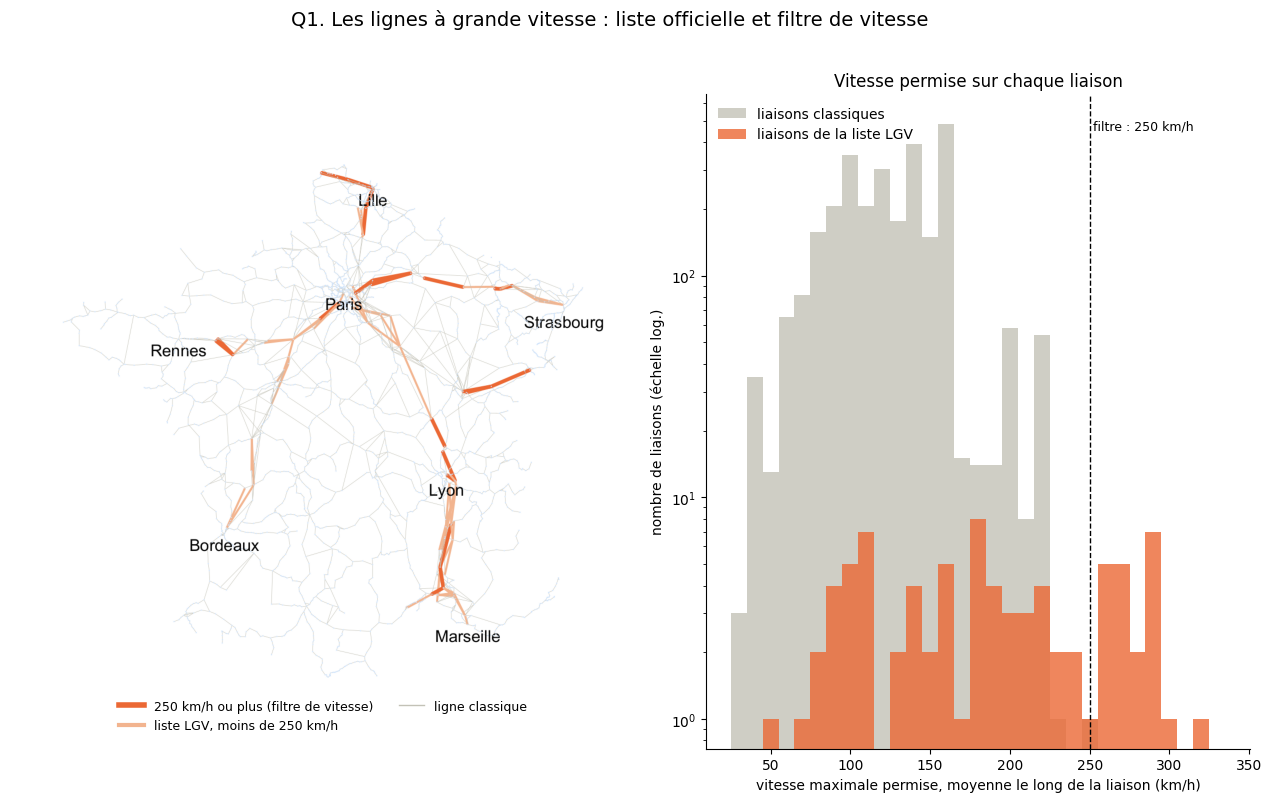

In [2]:
# 1. Filtre de vitesse : Select → Filter → Column Filter sur la colonne vitesse_kmh
p4c.create_column_filter("grande vitesse", "vitesse_kmh", [250, 400], "BETWEEN", type="edges", network=BASE)
selection = p4c.get_table_columns("edge", ["cle", "selected"], network=BASE)
rapides = set(selection.cle[selection.selected.astype(str).str.lower() == "true"])
p4c.clear_selection(network=BASE)

# 2. Confrontation avec la liste officielle des lignes à grande vitesse (colonne type_ligne)
categorie = pd.Series("classique", index=liaisons.cle)
categorie[liaisons.cle[liaisons.type_ligne == "LGV"]] = "liste LGV, moins de 250 km/h"
categorie[list(rapides)] = "250 km/h ou plus"
colonne(categorie, "grande_vitesse", table="edge")
print(pd.crosstab(categorie.values, liaisons.set_index("cle").type_ligne[categorie.index].values,
                  rownames=["filtre de vitesse"], colnames=["liste officielle"]))
km = liaisons.set_index("cle").longueur_km
print(f"Liaisons à 250 km/h ou plus : {len(rapides)}, {km[list(rapides)].sum():.0f} km")

# 3. Style : couleur et épaisseur par catégorie (Discrete Mapping)
etiquettes(["75056", "69123", "13055", "33063", "59350", "67482", "35238"])
style("Q1", noeud=3)
valeurs = ["250 km/h ou plus", "liste LGV, moins de 250 km/h", "classique"]
p4c.set_edge_color_mapping("grande_vitesse", valeurs, [ORANGE, "#f2b48f", GRIS], mapping_type="d", style_name="Q1")
p4c.set_edge_line_width_mapping("grande_vitesse", valeurs, [9, 5, 1], mapping_type="d", style_name="Q1")


def histogramme_vitesse(ax):
    bornes = np.arange(25, 340, 10)
    for type_ligne, couleur in [("classique", GRIS), ("LGV", ORANGE)]:
        ax.hist(liaisons.vitesse_kmh[liaisons.type_ligne == type_ligne].dropna(), bins=bornes, color=couleur,
                alpha=0.8, label=f"liaisons {'de la liste LGV' if type_ligne == 'LGV' else 'classiques'}")
    ax.axvline(250, color="black", lw=1, ls="--")
    ax.annotate("filtre : 250 km/h", (252, ax.get_ylim()[1] * 0.9), fontsize=9)
    ax.set_yscale("log")
    ax.set_xlabel("vitesse maximale permise, moyenne le long de la liaison (km/h)")
    ax.set_ylabel("nombre de liaisons (échelle log.)")
    ax.set_title("Vitesse permise sur chaque liaison")
    ax.legend(frameon=False, loc="upper left")


figure("Q1_lgv", "Q1. Les lignes à grande vitesse : liste officielle et filtre de vitesse", panneaux=[histogramme_vitesse],
       legende=[trait(ORANGE, 4, "250 km/h ou plus (filtre de vitesse)"), trait("#f2b48f", 3, "liste LGV, moins de 250 km/h"),
                trait(GRIS, 1, "ligne classique")])

*Figure 1.* À gauche, le réseau des villes dans Cytoscape, chaque ville placée à ses coordonnées. En orange vif, les liaisons retenues par le filtre de vitesse de Cytoscape (vitesse permise moyenne de 250 km/h ou plus). En orange pâle, les liaisons de la liste officielle des lignes à grande vitesse que le filtre ne retient pas. En gris, les lignes classiques. À droite, la distribution de la vitesse permise sur les liaisons ; la ligne pointillée marque le seuil du filtre.

**Réponse :** les lignes à grande vitesse forment une étoile centrée sur Paris, à quatre branches : vers Lyon et Marseille au sud-est, vers Bordeaux et Rennes à l'ouest, vers Lille au nord, vers Strasbourg à l'est. Les deux méthodes concordent : aucune ligne classique ne passe le filtre de vitesse. Le filtre est pourtant plus sévère que la liste. Seules 22 des 82 liaisons de la liste roulent en moyenne à 250 km/h ou plus, toutes en pleine ligne et sans arrêt. Les autres mêlent un tronçon à grande vitesse et une entrée de ville ou un raccordement plus lents. Un attribut d'arête, filtré dans Cytoscape, suffit ainsi à faire apparaître la structure en étoile du réseau.

**Q2. Où circulent les trains ?**

*Notions du cours.* Un **graphe pondéré** associe un poids $w(e)$ à chaque arête $e$. Le même graphe peut porter plusieurs poids : ici la longueur en km (l'infrastructure) et le nombre de trains par jour (le service), un mardi ordinaire, deux sens confondus. Cette question pondère les arêtes par le nombre de trains.

*Dans Cytoscape.* `set_edge_line_width_mapping` et `set_edge_color_mapping` sans `mapping_type` (Style › Edge › Width et Stroke Color › Continuous Mapping) : l'épaisseur et la teinte de chaque liaison varient continûment avec sa colonne `nb_trains_jour`.

Liaisons sans aucun train ce jour-là : 20%


,de,vers,nb_trains_jour,longueur_km
688,Eckwersheim,Mundolsheim,321,3.692
1621,Mundolsheim,Strasbourg,321,7.770
90,Montgeron,Yerres,301,1.674
148,Combs-la-Ville,Boussy-Saint-Antoine,301,2.149
174,Brunoy,Yerres,301,2.303


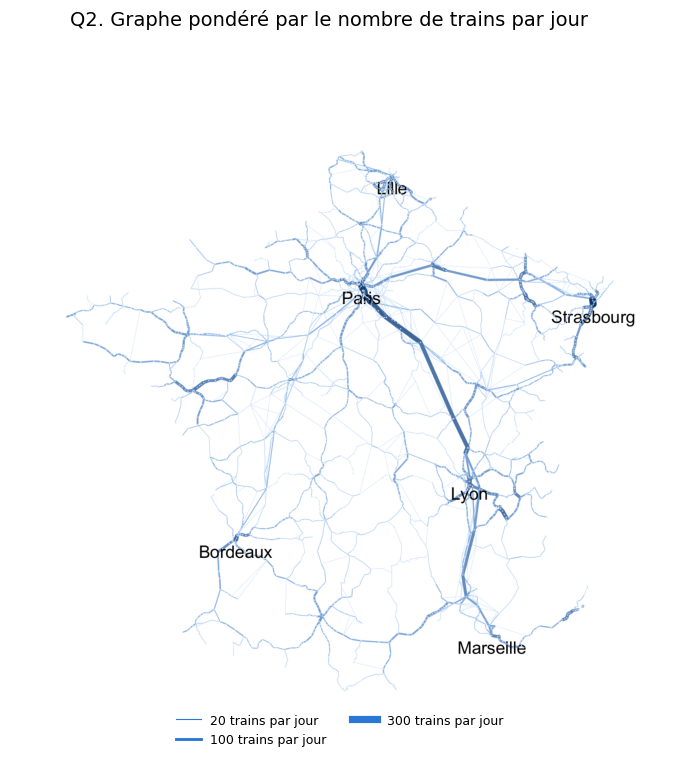

In [3]:
maxi = float(liaisons.nb_trains_jour.max())
etiquettes(["75056", "69123", "59350", "67482", "13055", "33063"])
style("Q2", noeud=3)
p4c.set_edge_line_width_mapping("nb_trains_jour", [0, maxi], [0.5, 16], style_name="Q2")
p4c.set_edge_color_mapping("nb_trains_jour", [0, maxi], ["#9ec5f4", FONCE], style_name="Q2")

print(f"Liaisons sans aucun train ce jour-là : {(liaisons.nb_trains_jour == 0).mean():.0%}")
display(liaisons.nlargest(5, "nb_trains_jour")
        .assign(de=lambda t: villes.nom[t.source].values, vers=lambda t: villes.nom[t.target].values)
        [["de", "vers", "nb_trains_jour", "longueur_km"]])
figure("Q2_trains", "Q2. Graphe pondéré par le nombre de trains par jour",
       legende=[trait(BLEU, 0.5 + 5 * n / maxi, f"{n} trains par jour") for n in (20, 100, 300)])

*Figure 2.* Le graphe pondéré par le service. L'épaisseur et la teinte de chaque liaison sont proportionnelles au nombre de trains qui l'empruntent un mardi ordinaire, deux sens confondus.

**Réponse :** les trains circulent surtout sur les grands axes qui partent de Paris (vers Lyon et Marseille, Lille, Strasbourg) et autour des métropoles régionales (Lyon, Lille, Strasbourg), où les TER dessinent de petites étoiles. La liaison la plus chargée est l'entrée nord de Strasbourg (321 trains par jour). Une liaison sur cinq n'a aucun train ce jour-là : ce sont surtout des liaisons de banlieue parisienne, dont les trains (Transilien, RER) manquent aux horaires utilisés, et des lignes fermées aux voyageurs. Pondérer par les trains plutôt que par les km montre un autre réseau : celui du service, beaucoup plus concentré que celui des voies.

**Q3. Quelles villes sont les plus connectées ?**

*Notions du cours.*
- Le **degré** $k(v)$ d'un nœud est son nombre de voisins. Le **degré pondéré** $s(v) = \sum_{u} w(u, v)$ additionne les poids de ses arêtes ; ici, les trains qui passent par ses liaisons.
- La **distribution des degrés** $p(k)$ est la part des nœuds de degré $k$. Dans un réseau **sans échelle**, comme les réseaux d'interactions de protéines du cours, elle suit une loi de puissance : quelques carrefours géants, nés de l'attachement préférentiel (Barabási).
- Le cours utilise aussi le degré pour repérer les métabolites trop connectés, comme l'eau ou l'ATP, qui créent de faux raccourcis.

*Dans Cytoscape.*
- `analyze_network` (Tools › Analyze Network) calcule la colonne `Degree` de chaque ville ;
- le degré pondéré, que Cytoscape ne calcule pas, est ajouté par `load_table_data` ;
- la taille des nœuds suit le degré et leur couleur le degré pondéré (deux correspondances continues).

,ville,degré (Cytoscape),degré pondéré (trains par jour)
21183,Collonges-et-Premières,13,214
77229,La Houssaye-en-Brie,13,0
77305,Montereau-Fault-Yonne,13,494
77470,Tournan-en-Brie,13,0
84019,Bollène,12,344


,ville,degré (Cytoscape),degré pondéré (trains par jour)
75056,Paris,11,957
69123,Lyon,6,874
67482,Strasbourg,4,664
67309,Mundolsheim,3,642
67119,Eckwersheim,7,641


Villes de degré 2 : 73% ; degré 1 (terminus) : 66


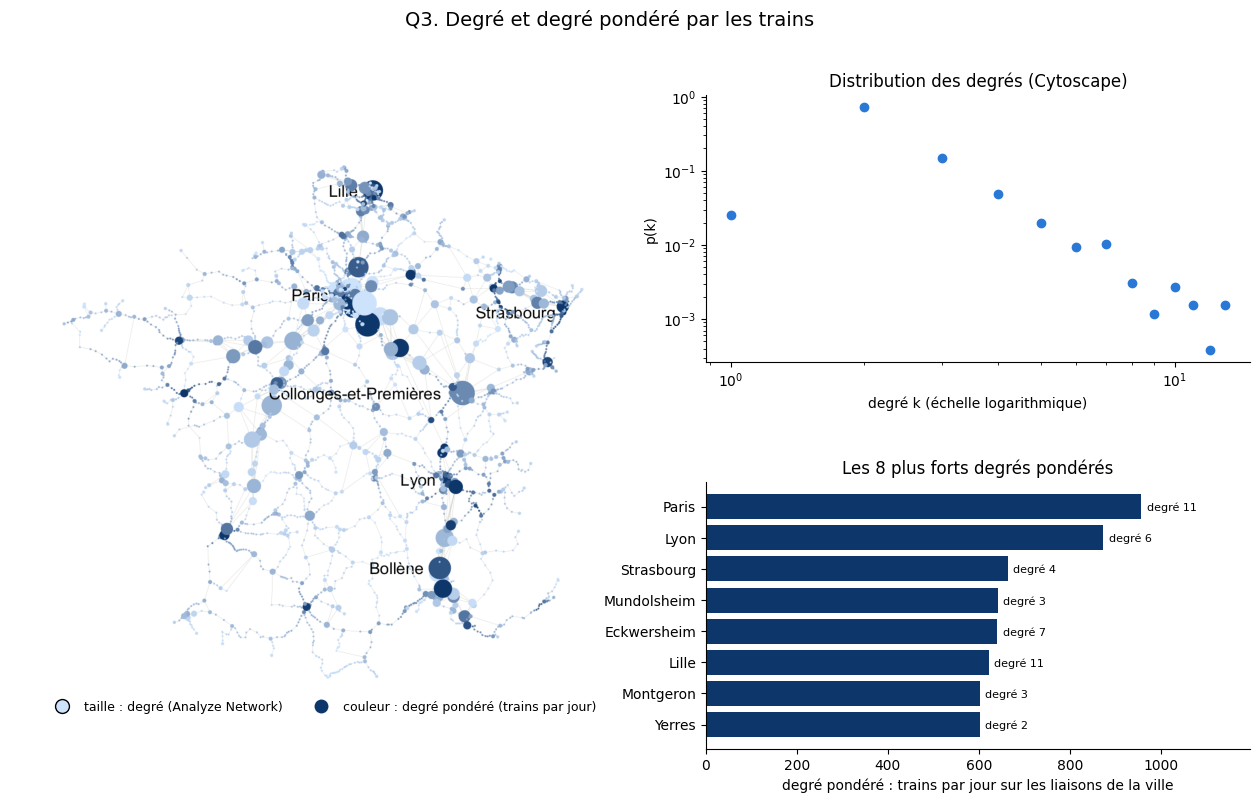

In [4]:
# Tools → Analyze Network sur le réseau des villes : colonne Degree (et statistiques globales, utilisées en Q4)
p4c.set_current_network(BASE)
analyse_base = p4c.analyze_network()
degre = p4c.get_table_columns("node", ["cle", "Degree"], network=BASE).set_index("cle").Degree.astype(int)
degre_pondere = pd.Series(dict(G.degree(weight="nb_trains_jour")))  # somme des trains des liaisons de chaque ville
colonne(degre_pondere, "degre_pondere")
tableau = pd.DataFrame({"ville": villes.nom, "degré (Cytoscape)": degre, "degré pondéré (trains par jour)": degre_pondere})
display(tableau.nlargest(5, "degré (Cytoscape)"))
display(tableau.nlargest(5, "degré pondéré (trains par jour)"))
print(f"Villes de degré 2 : {(degre == 2).mean():.0%} ; degré 1 (terminus) : {(degre == 1).sum()}")

hors_idf = lambda ids: [v for v in ids if v not in IDF]
nommees = ["75056", "69123", "67482", "59350"] + hors_idf(degre.nlargest(10).index)[:2]  # Paris, Lyon, Strasbourg, Lille
etiquettes(nommees)
style("Q3", noeud=4, arete=0.6)
p4c.set_visual_property_default({"visualProperty": "NODE_LABEL_POSITION", "value": "W,E,r,-12.00,0.00"}, style_name="Q3")  # étiquettes à gauche des nœuds
p4c.set_node_size_mapping("Degree", [1, 2, float(degre.max())], [8, 5, 60], style_name="Q3")
p4c.set_node_color_mapping("degre_pondere", [0, float(degre_pondere.quantile(0.99))], [CLAIR, FONCE], style_name="Q3")


def distribution(ax):
    pk = degre[degre > 0].value_counts(normalize=True).sort_index()
    ax.loglog(pk.index, pk.values, "o", color=BLEU)
    ax.set_xlabel("degré k (échelle logarithmique)")
    ax.set_ylabel("p(k)")
    ax.set_title("Distribution des degrés (Cytoscape)")


def classement(ax):
    top = degre_pondere.nlargest(8)[::-1]
    ax.barh([villes.nom[v] for v in top.index], top.values, color=FONCE)
    for i, v in enumerate(top.index):
        ax.annotate(f"degré {degre[v]}", (top[v], i), xytext=(4, -3), textcoords="offset points", fontsize=8)
    ax.set_xlim(0, top.max() * 1.25)
    ax.set_xlabel("degré pondéré : trains par jour sur les liaisons de la ville")
    ax.set_title("Les 8 plus forts degrés pondérés")


figure("Q3_degre", "Q3. Degré et degré pondéré par les trains", panneaux=[distribution, classement],
       legende=[point(CLAIR, 10, "taille : degré (Analyze Network)", bord="black"),
                point(FONCE, 10, "couleur : degré pondéré (trains par jour)")])

*Figure 3.* À gauche, le réseau des villes ; la taille des nœuds code le degré calculé par Cytoscape, leur couleur le degré pondéré par les trains. En haut à droite, la distribution des degrés en échelles logarithmiques ; en bas à droite, les villes au plus fort degré pondéré, avec leur degré.

**Réponse :** cela dépend du poids choisi. **Sans poids**, le plus fort degré n'est que de 13. Il revient à des villes comme Montereau-Fault-Yonne ou Collonges-et-Premières, situées au bord d'une ligne sans gare (contournement fret ou ligne à grande vitesse) : le prétraitement les relie à toutes les villes que cette ligne atteint. C'est un artefact de construction, que le cours invite justement à vérifier. **Pondéré par les trains**, le classement devient celui que l'on attend : Paris (957 trains par jour sur ses liaisons), Lyon (874), Strasbourg (664). Suivent des villes de passage sur les entrées les plus chargées, comme Mundolsheim et Eckwersheim aux portes de Strasbourg : le degré pondéré mesure le trafic qui passe, pas seulement celui qui s'arrête. Le réseau n'a pas de carrefour géant. Près de trois villes sur quatre (73 %) ont un degré 2, au milieu d'une ligne, et la distribution chute très vite, sans la longue traîne d'un réseau sans échelle. La géographie limite le nombre de voies qui peuvent partir d'une gare, alors qu'un métabolite comme l'ATP participe à des centaines de réactions.

**Q4. Le réseau ferré est-il un « petit monde » ?**

*Notions du cours.*
- Un **petit monde** (Milgram, les « six degrés de séparation ») combine deux propriétés : une longueur moyenne des plus courts chemins $L$ faible, de l'ordre de $\log n$, et un fort **coefficient de regroupement**.
- Le coefficient de regroupement d'un nœud, $C(v) = \dfrac{2\,T(v)}{k(v)\,(k(v)-1)}$, est la part de ses paires de voisins qui sont reliées entre elles ; $T(v)$ est le nombre de triangles qui passent par $v$.
- Ces deux mesures se comparent à un **graphe aléatoire** de même taille (Erdős-Rényi) : même nombre de nœuds et d'arêtes, arêtes tirées au hasard.

*Dans Cytoscape.* `analyze_network` (Tools › Analyze Network, lancé en Q3) renvoie $L$ (`avSpl`) et le regroupement moyen (`cc`) du réseau, ainsi que la colonne `ClusteringCoefficient` de chaque ville, dessinée ici par correspondance continue.

,réseau ferré (Cytoscape),graphe aléatoire (moyenne de 10)
longueur moyenne des chemins L (liaisons),25.859,8.461
coefficient de regroupement moyen,0.058,0.001


log(n) = 7.9


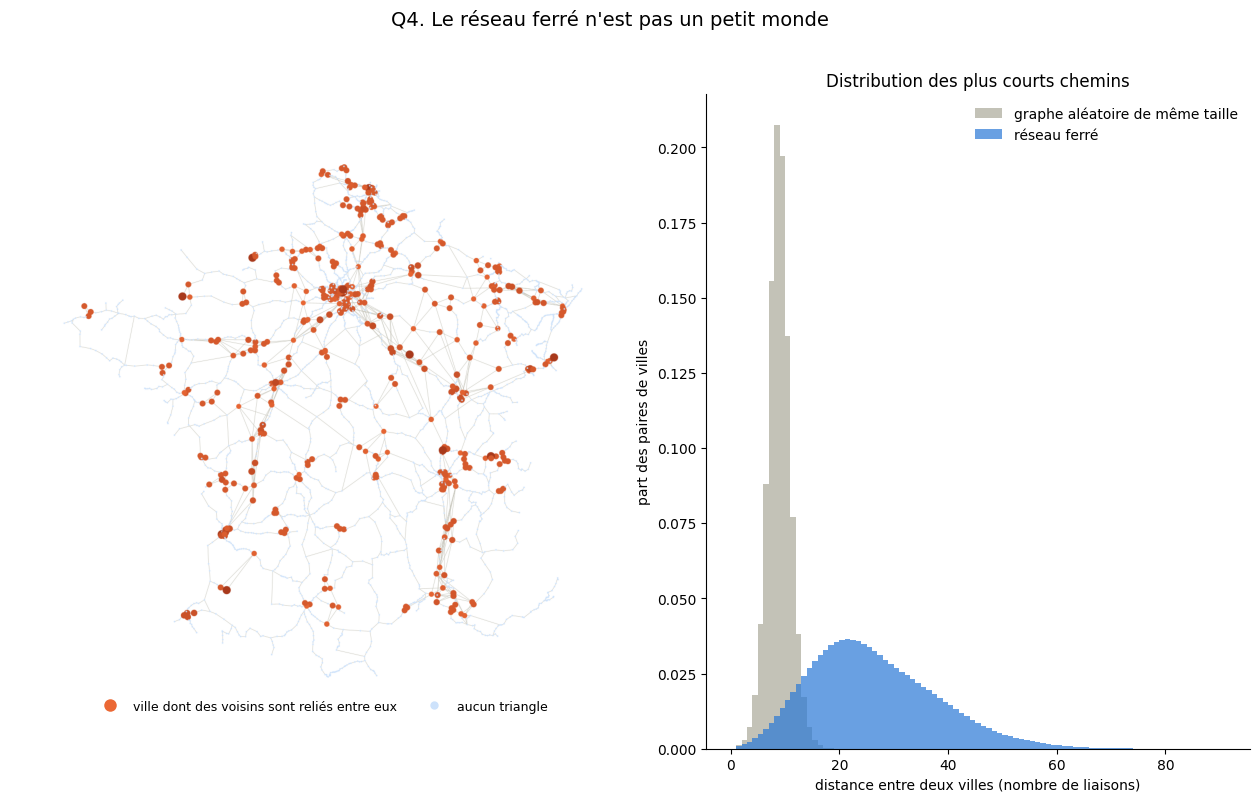

In [5]:
n, m = P.number_of_nodes(), P.number_of_edges()
reel = {"longueur moyenne des chemins L (liaisons)": float(analyse_base["avSpl"]),
        "coefficient de regroupement moyen": float(analyse_base["cc"])}
aleatoires = []
for graine in range(10):
    A = nx.gnm_random_graph(n, m, seed=graine)
    A = A.subgraph(max(nx.connected_components(A), key=len))
    aleatoires.append({"longueur moyenne des chemins L (liaisons)": nx.average_shortest_path_length(A),
                       "coefficient de regroupement moyen": nx.average_clustering(A)})
display(pd.DataFrame({"réseau ferré (Cytoscape)": reel, "graphe aléatoire (moyenne de 10)": pd.DataFrame(aleatoires).mean()}).round(3))
print(f"log(n) = {np.log(n):.1f}")


def distances(H):  # distance en nombre de liaisons entre toutes les paires de villes
    return pd.Series([d for _, dist in nx.all_pairs_shortest_path_length(H) for d in dist.values() if d > 0])


d_reel, d_alea = distances(P), distances(A)

etiquettes([])
style("Q4", noeud=4)
p4c.set_node_color_mapping("ClusteringCoefficient", [0, 0.01, 1], [CLAIR, ORANGE, "#a8391b"], style_name="Q4")
p4c.set_node_size_mapping("ClusteringCoefficient", [0, 0.01, 1], [4, 12, 20], style_name="Q4")


def histogramme(ax):
    bornes = np.arange(0, d_reel.max() + 2)
    ax.hist(d_alea, bins=bornes, density=True, color=GRIS, label="graphe aléatoire de même taille")
    ax.hist(d_reel, bins=bornes, density=True, color=BLEU, alpha=0.7, label="réseau ferré")
    ax.set_xlabel("distance entre deux villes (nombre de liaisons)")
    ax.set_ylabel("part des paires de villes")
    ax.set_title("Distribution des plus courts chemins")
    ax.legend(frameon=False)


figure("Q4_petit_monde", "Q4. Le réseau ferré n'est pas un petit monde", panneaux=[histogramme],
       legende=[point(ORANGE, 9, "ville dont des voisins sont reliés entre eux"), point(CLAIR, 6, "aucun triangle")])

*Figure 4.* À gauche, les villes colorées selon leur coefficient de regroupement calculé par Cytoscape : en orange, au moins deux de leurs voisins sont reliés entre eux et forment un triangle. À droite, la distribution des distances entre toutes les paires de villes, en nombre de liaisons, pour le réseau ferré (bleu) et pour un graphe aléatoire de même taille (gris).

**Réponse :** non. Le réseau ferré a bien un regroupement plus fort qu'un graphe aléatoire (0,058 contre environ 0,001), grâce aux triangles des nœuds ferroviaires et de la banlieue parisienne. Mais ses chemins sont trois fois plus longs : 26 liaisons en moyenne pour aller d'une ville à une autre, et jusqu'à 90, contre 8,5 dans le graphe aléatoire, valeur proche de log(n) ≈ 7,9. Les gares s'enchaînent le long des lignes comme les perles d'un collier, sans les raccourcis qui font un petit monde. La géographie interdit les liaisons lointaines, à l'exception des lignes à grande vitesse.

**Q5. Où est le centre du réseau, où est sa périphérie ?**

*Notions du cours.*
- La distance $d(x, y)$ est la longueur du plus court chemin, en km, calculée par l'algorithme de Dijkstra.
- La **centralité de proximité** du cours est $C(x) = \dfrac{1}{\sum_y d(y, x)}$. Son **inverse**, l'éloignement $\sum_y d(y, x)$, est la somme des distances de $x$ à toutes les autres villes. Divisé par $n - 1$, c'est la distance moyenne ; Cytoscape et NetworkX normalisent ainsi la proximité : $(n-1)/\sum_y d(y,x)$.
- L'**excentricité** $e(x) = \max_y d(x, y)$ ne garde que la plus grande de ces distances : la distance à la ville la plus éloignée.
- Le **rayon** est l'excentricité minimale, atteinte au **centre**. Le **diamètre** est l'excentricité maximale, atteinte à la **périphérie**.

*Dans Cytoscape.*
- les colonnes `excentricite` et `eloignement`, calculées en km par NetworkX, sont ajoutées par `load_table_data` ;
- la couleur suit l'excentricité (correspondance continue) ; la forme et la taille marquent le centre et la périphérie (`set_node_shape_mapping`, correspondance discrète) ;
- le diamètre est dessiné en orange par une colonne d'arête.

,ville,éloignement : distance moyenne (km),excentricité (km)
03185,Montluçon,401.0,746.0
03082,Commentry,404.0,753.0
03301,Vaux,403.0,753.0
91216,Épinay-sur-Orge,375.0,979.0
91326,Juvisy-sur-Orge,375.0,974.0
91027,Athis-Mons,376.0,977.0
06162,La Brigue,895.0,1487.0
29019,Brest,814.0,1487.0
06163,Tende,892.0,1483.0


Rayon : 746 km ; diamètre : 1487 km (La Brigue → Brest, 144 villes traversées)


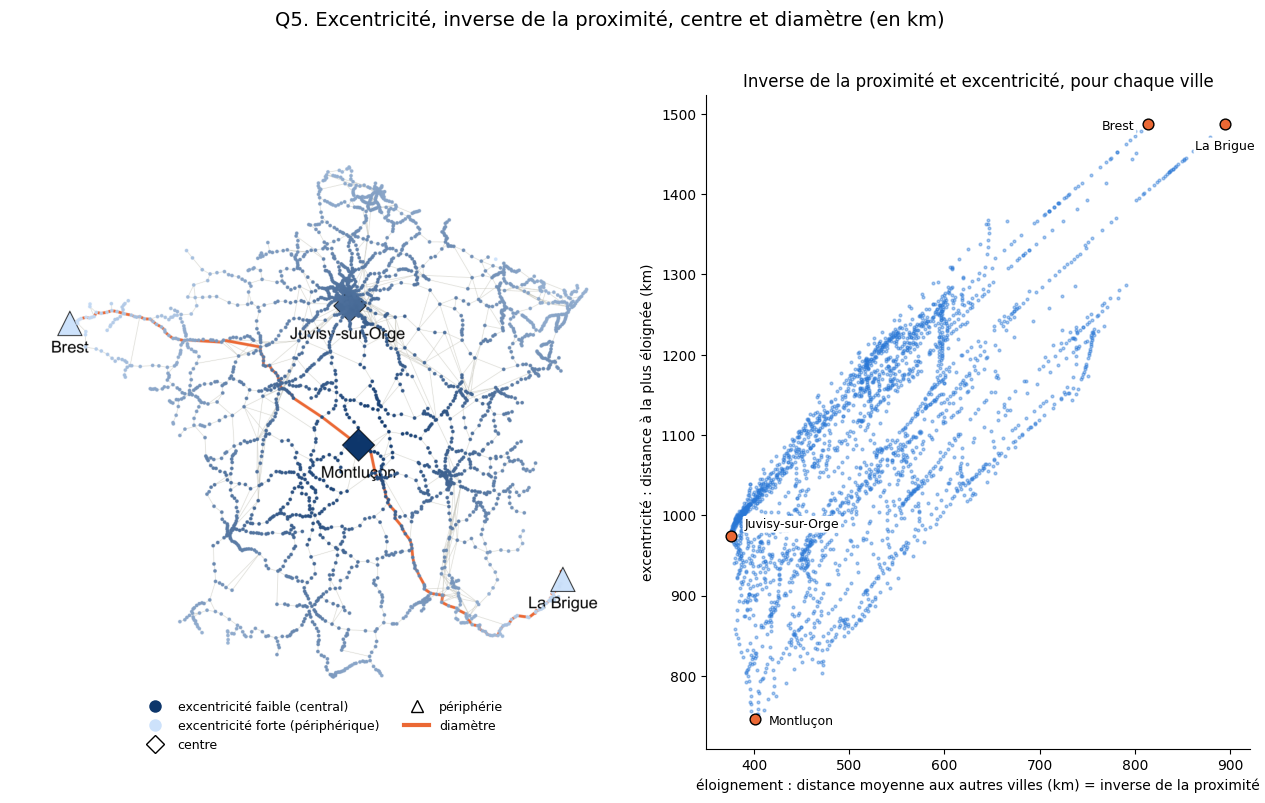

In [6]:
proximite = pd.Series(nx.closeness_centrality(P, distance=KM))  # (n-1) / somme des distances
eloignement = 1 / proximite                                       # inverse : distance moyenne (km)
excentricite = pd.Series(nx.eccentricity(P, weight=KM))           # distance à la ville la plus éloignée (km)
centre, proche = excentricite.idxmin(), eloignement.idxmin()
bout1, bout2 = excentricite[excentricite == excentricite.max()].index[[0, -1]]
diametre = nx.shortest_path(P, bout1, bout2, weight=KM)
mesures = pd.DataFrame({"ville": villes.nom, "éloignement : distance moyenne (km)": eloignement.round(0),
                        "excentricité (km)": excentricite.round(0)}).dropna()
display(pd.concat([mesures.nsmallest(3, "excentricité (km)"), mesures.nsmallest(3, "éloignement : distance moyenne (km)"),
                   mesures.nlargest(3, "excentricité (km)")]).drop_duplicates())
print(f"Rayon : {excentricite.min():.0f} km ; diamètre : {excentricite.max():.0f} km "
      f"({villes.nom[bout1]} → {villes.nom[bout2]}, {len(diametre) - 2} villes traversées)")

colonne(excentricite, "excentricite")
colonne(eloignement, "eloignement")
role = pd.Series("", index=villes.index)
role[[centre, proche]] = "centre"
role[[bout1, bout2]] = "périphérie"
colonne(role, "role_q5")
chemin = pd.Series("", index=liaisons.cle)
chemin[[cle_arete(a, b) for a, b in zip(diametre, diametre[1:])]] = "diamètre"
colonne(chemin, "chemin_q5", table="edge")
etiquettes([centre, proche, bout1, bout2])

style("Q5", noeud=9)
p4c.set_node_color_mapping("excentricite", [float(excentricite.min()), float(excentricite.max())], [FONCE, CLAIR], style_name="Q5")
p4c.set_node_size_mapping("role_q5", ["centre", "périphérie"], [80, 60], mapping_type="d", style_name="Q5")
p4c.set_node_shape_mapping("role_q5", ["centre", "périphérie"], ["DIAMOND", "TRIANGLE"], style_name="Q5")
p4c.set_node_border_width_mapping("role_q5", ["centre", "périphérie"], [4, 4], mapping_type="d", style_name="Q5")
p4c.set_edge_color_mapping("chemin_q5", ["diamètre"], [ORANGE], mapping_type="d", style_name="Q5")
p4c.set_edge_line_width_mapping("chemin_q5", ["diamètre"], [7], mapping_type="d", style_name="Q5")


def nuage(ax):
    ax.scatter(eloignement, excentricite[eloignement.index], s=4, color=BLEU, alpha=0.4)
    gauche, droite = sorted([bout1, bout2], key=eloignement.get)  # les deux villes de la périphérie
    for v, (dx, dy, cote) in {centre: (10, -4, "left"), proche: (10, 6, "left"),
                              gauche: (-10, -4, "right"), droite: (0, -18, "center")}.items():
        ax.scatter(eloignement[v], excentricite[v], s=60, color=ORANGE, edgecolors="black", zorder=3)
        ax.annotate(villes.nom[v], (eloignement[v], excentricite[v]), xytext=(dx, dy), textcoords="offset points",
                    ha=cote, fontsize=9, bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none"))
    ax.set_xlabel("éloignement : distance moyenne aux autres villes (km) = inverse de la proximité")
    ax.set_ylabel("excentricité : distance à la plus éloignée (km)")
    ax.set_title("Inverse de la proximité et excentricité, pour chaque ville")


figure("Q5_centre", "Q5. Excentricité, inverse de la proximité, centre et diamètre (en km)", panneaux=[nuage],
       legende=[point(FONCE, 9, "excentricité faible (central)"), point(CLAIR, 9, "excentricité forte (périphérique)"),
                point("white", 9, "centre", bord="black", forme="D"), point("white", 9, "périphérie", bord="black", forme="^"),
                trait(ORANGE, 3, "diamètre")])

*Figure 5.* À gauche, les villes colorées selon leur excentricité en km (foncé : la ville la plus éloignée est proche ; clair : elle est loin). Les losanges marquent les deux centres, les triangles les deux villes de la périphérie, et le tracé orange est le diamètre. À droite, chaque point est une ville : en abscisse l'inverse de la proximité (sa distance moyenne aux autres villes), en ordonnée son excentricité.

**Réponse :** le centre dépend de la mesure, comme le dit le cours (*« l'importance dépend du contexte »*). L'**excentricité** place le centre à Montluçon, au milieu géographique du pays : aucune ville n'en est à plus de 746 km, c'est le rayon du graphe. L'**inverse de la proximité** le place à Juvisy-sur-Orge, au sud de Paris, à 375 km en moyenne de toutes les autres villes, là où se concentre la masse des villes. Les deux mesures sont liées (le nuage monte), mais la première regarde le pire cas et la seconde la moyenne. La périphérie oppose Brest et La Brigue (Alpes-Maritimes) : 1 487 km de voie, le plus long des plus courts chemins de France, c'est-à-dire le diamètre.

**Q6. Quels sont les points névralgiques du réseau ?**

*Notions du cours.*
- La **centralité d'intermédiarité** d'un nœud $v$ est $C_B(v) = \sum_{s \neq v \neq t} \dfrac{\sigma_{st}(v)}{\sigma_{st}}$, où $\sigma_{st}$ est le nombre de plus courts chemins entre $s$ et $t$ et $\sigma_{st}(v)$ le nombre de ceux qui passent par $v$. Elle se calcule par l'algorithme de Brandes et s'étend aux arêtes.
- Le cours rappelle que le choix d'une centralité dépend du **type de flux** (typologie de Borgatti). Un voyageur, comme un colis, est *transféré* d'une ville à l'autre par le plus court chemin. Pour ce type de flux, le tableau du cours recommande la proximité et l'intermédiarité de Freeman : l'intermédiarité est donc la bonne mesure des points de passage obligés.

*Dans Cytoscape.*
- la taille et la couleur des villes suivent l'intermédiarité, et l'épaisseur des liaisons celle des arêtes (correspondances continues) ;
- les 10 points névralgiques sont entourés d'un contour noir (`set_node_border_width_mapping`, correspondance discrète) et numérotés ;
- une seconde vue agrandit le nord de Paris, où ils se concentrent (`set_network_zoom_bypass`, `set_network_center_bypass`).

,ville,intermédiarité,voyageurs 2025 (millions)
rang,,,
1,Paris,0.290,793.3
2,Saint-Denis,0.163,76.1
3,Creil,0.140,7.4
4,Vierzon,0.139,1.7
5,Lyon,0.133,62.9
6,Garges-lès-Gonesse,0.132,23.7
7,Arnouville,0.132,13.4
8,Goussainville,0.132,8.0
9,Louvres,0.131,2.6


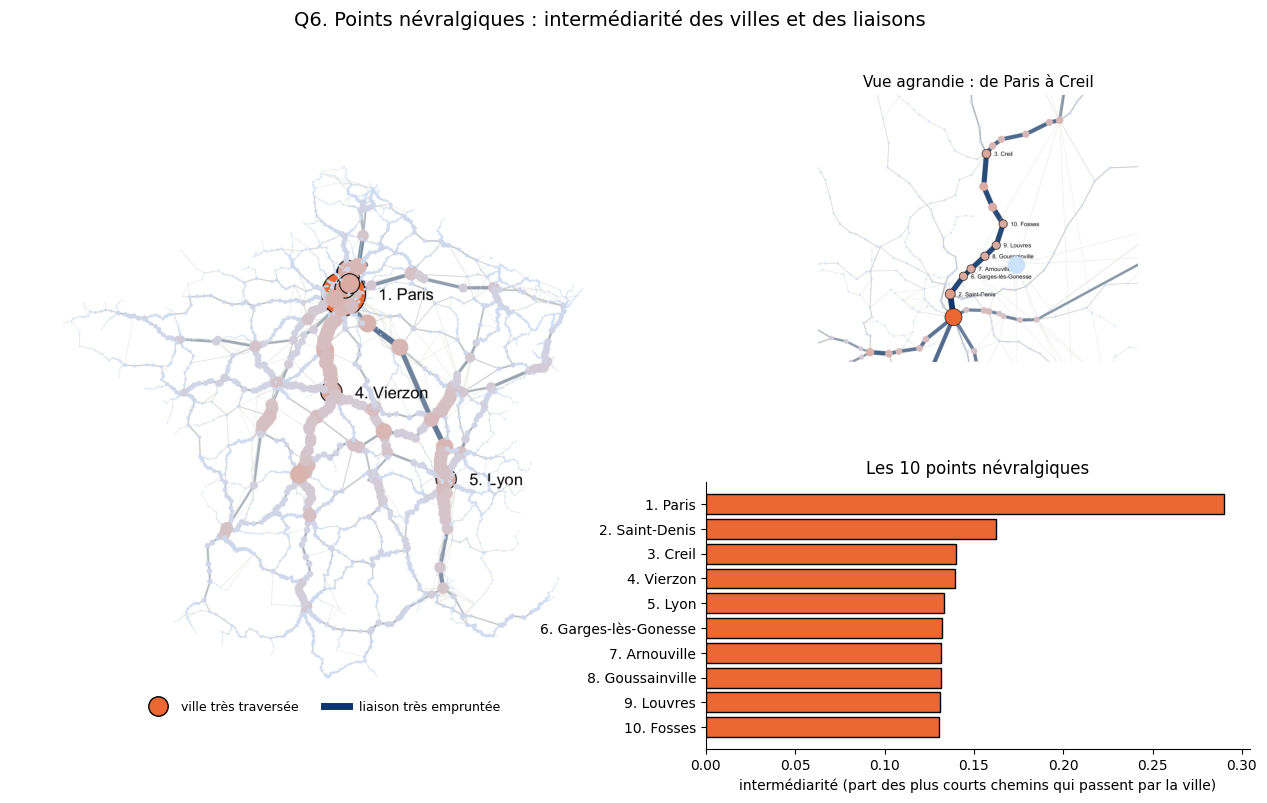

In [7]:
intermediarite = pd.Series(nx.betweenness_centrality(P, weight=KM))
inter_arete = nx.edge_betweenness_centrality(P, weight=KM)
liaisons["intermediarite"] = [inter_arete.get((a, b), inter_arete.get((b, a), 0)) for a, b in zip(liaisons.source, liaisons.target)]
top10 = list(intermediarite.nlargest(10).index)  # les 10 points névralgiques
display(pd.DataFrame({"rang": range(1, 11), "ville": villes.nom[top10], "intermédiarité": intermediarite[top10].round(3),
                      "voyageurs 2025 (millions)": (villes.voyageurs_2025[top10] / 1e6).round(1)}).set_index("rang"))

colonne(intermediarite, "intermediarite")
colonne(liaisons.set_index("cle").intermediarite, "intermediarite", table="edge")
role = pd.Series("", index=villes.index)
role[top10] = "névralgique"
colonne(role, "role_q6")
numeros = [f"{i}. {villes.nom[v]}" for i, v in enumerate(top10, start=1)]
style("Q6")
imax, emax = float(intermediarite.max()), float(liaisons.intermediarite.max())
p4c.set_node_size_mapping("intermediarite", [0, imax], [3, 110], style_name="Q6")
p4c.set_node_color_mapping("intermediarite", [0, imax], [CLAIR, ORANGE], style_name="Q6")
p4c.set_node_border_width_mapping("role_q6", ["névralgique"], [5], mapping_type="d", style_name="Q6")
p4c.set_node_border_color_default("#000000", style_name="Q6")
p4c.set_edge_line_width_mapping("intermediarite", [0, emax], [0.8, 22], style_name="Q6")
p4c.set_edge_color_mapping("intermediarite", [0, emax], ["#d9d8d0", FONCE], style_name="Q6")

# vue de la France : on nomme les points névralgiques hors de la région parisienne
au_nord = lambda v: villes.lat[v] > 48.9  # de Saint-Denis à Creil : montrés dans la vue agrandie
etiquettes([v for v in top10 if not au_nord(v)], [n for v, n in zip(top10, numeros) if not au_nord(v)])
p4c.set_visual_property_default({"visualProperty": "NODE_LABEL_POSITION", "value": "E,W,l,30.00,0.00"}, style_name="Q6")
france = exporter("Q6_intermediarite_cytoscape")
# vue agrandie du nord de Paris : tous les points névralgiques de la région. L'agrandissement grossit aussi
# les nœuds et les textes : on réduit donc tailles, épaisseurs et police, et on place les étiquettes à droite.
etiquettes([v for v in top10 if au_nord(v)], [n for v, n in zip(top10, numeros) if au_nord(v)])
p4c.set_node_size_mapping("intermediarite", [0, imax], [0.6, 6], style_name="Q6")
p4c.set_edge_line_width_mapping("intermediarite", [0, emax], [0.1, 2], style_name="Q6")
p4c.set_node_border_width_mapping("role_q6", ["névralgique"], [0.4], mapping_type="d", style_name="Q6")
p4c.set_node_font_size_default(2.2, style_name="Q6")
p4c.set_visual_property_default({"visualProperty": "NODE_LABEL_POSITION", "value": "E,W,l,1.00,0.00"}, style_name="Q6")
zoom_paris = exporter("Q6_zoom_paris_cytoscape", centre=(2.44, 49.09), facteur=14)


def classement(ax):
    ax.barh(numeros[::-1], intermediarite[top10][::-1], color=ORANGE, edgecolor="black")
    ax.set_xlabel("intermédiarité (part des plus courts chemins qui passent par la ville)")
    ax.set_title("Les 10 points névralgiques")


composer("Q6_intermediarite", "Q6. Points névralgiques : intermédiarité des villes et des liaisons", france,
         panneaux=[lambda ax: montrer(ax, zoom_paris, "Vue agrandie : de Paris à Creil"), classement],
         legende=[point(ORANGE, 14, "ville très traversée", bord="black"), trait(FONCE, 5, "liaison très empruntée")])

*Figure 6.* À gauche, la taille et la couleur des villes codent leur intermédiarité, de bleu clair à orange ; l'épaisseur et la teinte des liaisons codent celle des arêtes. Les 10 points névralgiques ont un contour noir et sont numérotés par rang. En haut à droite, une vue agrandie dans Cytoscape de la ligne de Saint-Denis à Creil, où se trouvent sept d'entre eux. En bas à droite, leur intermédiarité.

**Réponse :** le premier point névralgique est Paris, par où passent 29 % de tous les plus courts chemins. Viennent ensuite sept villes alignées sur la ligne qui relie Paris au nord : Saint-Denis, Creil, Garges-lès-Gonesse, Arnouville, Goussainville, Louvres et Fosses. Tout trajet vers Lille, la Belgique ou la Picardie les traverse. Loin de Paris, seuls Vierzon (Cher) et Lyon complètent la liste. Vierzon, petite gare de 1,7 million de voyageurs par an, est incontournable parce que s'y croisent l'axe Paris-Toulouse et la transversale Nantes-Lyon : comme un métabolite par lequel passent de nombreuses voies, son importance tient à sa position et non à sa taille. Les liaisons les plus épaisses dessinent l'ossature du réseau : Paris-Orléans-Limoges-Toulouse et Paris-Lyon-Marseille.

**Q7. Que se passe-t-il si l'on retire les 10 points névralgiques ?**

*Notions du cours.*
- La **robustesse** d'un réseau se mesure en retirant des nœuds et en observant la **plus grande composante connexe** (la part des villes encore reliées entre elles) et la longueur des plus courts chemins.
- Le cours oppose deux scénarios : les **pannes au hasard**, que les réseaux sans échelle supportent bien, et l'**attaque ciblée** contre les nœuds les plus centraux, qui les fait s'effondrer.
- Un **point d'articulation** est un nœud dont le retrait coupe le graphe en morceaux, comme les **points d'étranglement** (choke points) des réseaux métaboliques, les réactions seules à produire ou consommer un métabolite.

*Dans Cytoscape.*
- `clone_network` (File › New Network › Clone Current Network) crée une copie du réseau, pour garder l'original intact ;
- `select_nodes` puis `delete_selected_nodes` (Select › Nodes, puis Edit › Delete Selected Nodes) y suppriment les 10 villes ;
- la couleur des villes restantes suit l'allongement de leur distance moyenne (correspondance continue). Les villes détachées du réseau, sans valeur, prennent la couleur par défaut, en orange.

Composantes connexes : 2 ; villes détachées : Orry-la-Ville, Chantilly


Allongement de la distance moyenne : 3.4 % en moyenne, 37.2 % au plus


,ville retirée,composantes,plus grande composante (%),trajets coupés (sur 300),allongement moyen des trajets (%)
0,aucune,1,100.00,0,0.00
1,Paris,1,99.96,0,0.83
2,Saint-Denis,1,99.92,0,1.09
3,Creil,1,99.88,0,2.32
4,Vierzon,1,99.85,0,3.82
5,Lyon,1,99.81,0,4.44
6,Garges-lès-Gonesse,1,99.77,0,4.44
7,Arnouville,1,99.73,0,4.44
8,Goussainville,2,99.54,0,4.44
9,Louvres,2,99.54,0,4.44


Points d'articulation : 318 (12% des villes)


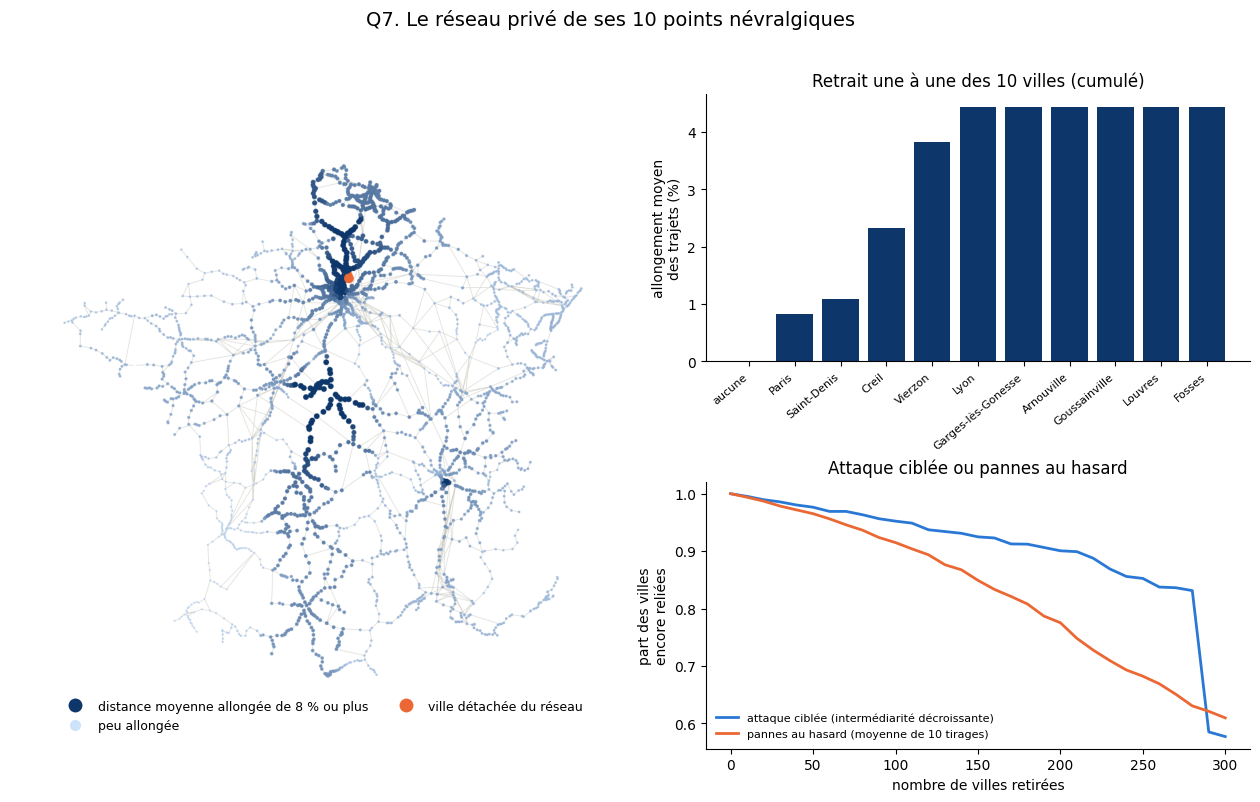

In [8]:
# 1. Dans Cytoscape : copie du réseau, sélection des 10 villes, suppression
#    (on retire aussi les 2 villes qui n'ont jamais fait partie du réseau principal, pour ne pas les confondre
#    avec les villes détachées par le retrait)
copie = p4c.clone_network(BASE)
p4c.select_nodes(top10 + [v for v in G if v not in P], by_col="cle", preserve_current_selection=False, network=copie)
p4c.delete_selected_nodes(network=copie)

# 2. Dans NetworkX : le même graphe sans les 10 villes
H = P.copy()
H.remove_nodes_from(top10)
principal = max(nx.connected_components(H), key=len)
detachees = set(H) - principal
print(f"Composantes connexes : {nx.number_connected_components(H)} ; villes détachées : {', '.join(villes.nom[list(detachees)])}")

# 3. Allongement de la distance moyenne de chaque ville restante (Dijkstra de scipy, toutes les paires d'un coup)
garde = list(principal)
ordre = garde + [v for v in P if v not in principal]
avant = dijkstra(nx.to_scipy_sparse_array(P, nodelist=ordre, weight=KM), directed=False)[:len(garde), :len(garde)]
apres = dijkstra(nx.to_scipy_sparse_array(H.subgraph(garde), nodelist=garde, weight=KM), directed=False)
allongement = pd.Series(100 * (apres.sum(axis=1) / avant.sum(axis=1) - 1), index=garde)
print(f"Allongement de la distance moyenne : {allongement.mean():.1f} % en moyenne, {allongement.max():.1f} % au plus")

# 4. Retrait une à une des 10 villes : composantes et 300 trajets tirés au hasard, les mêmes à chaque étape
random.seed(2)
autres = [v for v in P if v not in top10]
paires = [tuple(random.sample(autres, 2)) for _ in range(300)]
reference = {(a, b): nx.shortest_path_length(P, a, b, weight=KM) for a, b in paires}
etapes, H2 = [], P.copy()
for v in [None] + top10:
    if v:
        H2.remove_node(v)
    allong, coupes = [], 0
    for a, b in paires:
        try:
            allong.append(nx.shortest_path_length(H2, a, b, weight=KM) / reference[(a, b)] - 1)
        except nx.NetworkXNoPath:
            coupes += 1
    etapes.append({"ville retirée": villes.nom[v] if v else "aucune", "composantes": nx.number_connected_components(H2),
                   "plus grande composante (%)": 100 * len(max(nx.connected_components(H2), key=len)) / len(P),
                   "trajets coupés (sur 300)": coupes, "allongement moyen des trajets (%)": 100 * np.mean(allong)})
etapes = pd.DataFrame(etapes)
display(etapes.round(2))

# 5. Comparaison avec le cours : attaque ciblée (intermédiarité décroissante) contre pannes au hasard
def part_reliee(ordre, n=300, pas=10):
    H3, resultat = P.copy(), {0: 1.0}
    for i, v in enumerate(ordre[:n], start=1):
        H3.remove_node(v)
        if i % pas == 0:
            resultat[i] = len(max(nx.connected_components(H3), key=len)) / len(P)
    return pd.Series(resultat)


attaque = part_reliee(list(intermediarite.sort_values(ascending=False).index))
random.seed(1)
panne = sum(part_reliee(random.sample(list(P), 300)) for _ in range(10)) / 10
articulations = list(nx.articulation_points(P))
print(f"Points d'articulation : {len(articulations)} ({len(articulations) / len(P):.0%} des villes)")

# 6. Style de la copie : couleur = allongement ; villes détachées (sans valeur) en orange, couleur par défaut
colonne(allongement, "allongement_pct", reseau=copie)
haut = float(allongement.quantile(0.95))  # échelle calée sur 95 % des villes, pour garder du contraste
style("Q7", copie, noeud=5, etiquette=None)
p4c.set_node_color_default(ORANGE, style_name="Q7")
p4c.set_node_color_mapping("allongement_pct", [0, haut], [CLAIR, FONCE], default_color=ORANGE, style_name="Q7")
p4c.set_node_size_mapping("allongement_pct", [0, haut], [4, 14], default_size=24, style_name="Q7")


def progression(ax):
    x = range(len(etapes))
    ax.bar(x, etapes["allongement moyen des trajets (%)"], color=FONCE)
    ax.set_xticks(list(x), etapes["ville retirée"], rotation=40, ha="right", fontsize=8)
    ax.set_ylabel("allongement moyen\ndes trajets (%)")
    ax.set_title("Retrait une à une des 10 villes (cumulé)")


def courbe(ax):
    ax.plot(attaque, color=BLEU, lw=2, label="attaque ciblée (intermédiarité décroissante)")
    ax.plot(panne, color=ORANGE, lw=2, label="pannes au hasard (moyenne de 10 tirages)")
    ax.set_xlabel("nombre de villes retirées")
    ax.set_ylabel("part des villes\nencore reliées")
    ax.set_title("Attaque ciblée ou pannes au hasard")
    ax.legend(frameon=False, loc="lower left", fontsize=8)


figure("Q7_sans_nevralgiques", "Q7. Le réseau privé de ses 10 points névralgiques", reseau=copie, panneaux=[progression, courbe],
       legende=[point(FONCE, 10, f"distance moyenne allongée de {haut:.0f} % ou plus"), point(CLAIR, 8, "peu allongée"),
                point(ORANGE, 10, "ville détachée du réseau")])

*Figure 7.* À gauche, la copie du réseau dans Cytoscape, privée de ses 10 points névralgiques. La couleur de chaque ville code l'allongement de sa distance moyenne aux autres villes ; en orange, les villes détachées du réseau. En haut à droite, l'allongement moyen de 300 trajets tirés au hasard, à mesure qu'on retire les 10 villes une à une. En bas à droite, la part des villes encore reliées quand on poursuit les retraits par ordre d'intermédiarité (attaque ciblée) ou au hasard (pannes).

**Réponse :** presque rien ne se coupe, mais tout s'allonge. Sans ses 10 points névralgiques, le réseau ne perd que 2 villes, Chantilly et Orry-la-Ville, isolées entre Creil et Louvres, et aucun des 300 trajets n'est coupé. Les trajets s'allongent en revanche de 4,4 % en moyenne. La distance moyenne de chaque ville aux autres augmente de 3,4 % en moyenne et jusqu'à 37 %, surtout au nord de Paris et autour de Vierzon, qu'il faut désormais contourner. Vierzon (+1,5 point), Creil (+1,2), Paris (+0,8) et Lyon (+0,6) pèsent le plus. Les cinq dernières villes retirées, sur la même ligne que Saint-Denis et Creil, n'ajoutent plus rien : une fois cette ligne coupée, plus aucun plus court chemin ne les traverse. Le réseau est redondant en son centre, car la grande ceinture contourne Paris.

Ses vraies fragilités sont en périphérie : 12 % des villes sont des points d'articulation, presque toutes sur des lignes en cul-de-sac. C'est pourquoi, contrairement à un réseau sans échelle, les pannes au hasard dégradent le réseau plus vite que l'attaque ciblée jusqu'à environ 280 retraits. Au-delà, l'attaque finit par le couper en deux.

**Q8. Quels trajets la promotion emprunte-t-elle pour venir à Rouen ?**

*Notions du cours.*
- Le **plus court chemin pondéré** se calcule par l'algorithme de Dijkstra (1959). Sa longueur sert de mesure de proximité entre deux nœuds.
- Le cours propose d'**extraire un sous-réseau** de taille interprétable en faisant l'**union des plus courts chemins** entre les nœuds d'intérêt.
- Il prévient aussi que le plus court chemin est une **hypothèse parcimonieuse**, qui ignore les itinéraires alternatifs et ne tient pas toujours dans la réalité.

*Dans Cytoscape.*
- `create_subnetwork` (File › New Network › From Selected Nodes, Selected Edges) extrait le sous-réseau formé par l'union des sept chemins ; le sous-réseau garde les positions géographiques ;
- la couleur de chaque liaison suit la colonne `trajet_rouen` (correspondance discrète) ;
- `set_node_property_bypass` (Set Bypass) déplace les étiquettes de Paris, Versailles et Évry, qui se chevauchaient.

,train_km,vol_oiseau_km,par_versailles,detour
Paris,133.05,115.394871,True,1.152998
Évry,153.692,136.994759,True,1.121882
Nantes,475.986,318.898214,False,1.492595
Dijon,438.003,382.262542,True,1.145817
Lyon,580.313,499.707105,True,1.161306
Toulouse,827.478,645.896695,True,1.281131
Montpellier,888.23,680.667845,True,1.304939


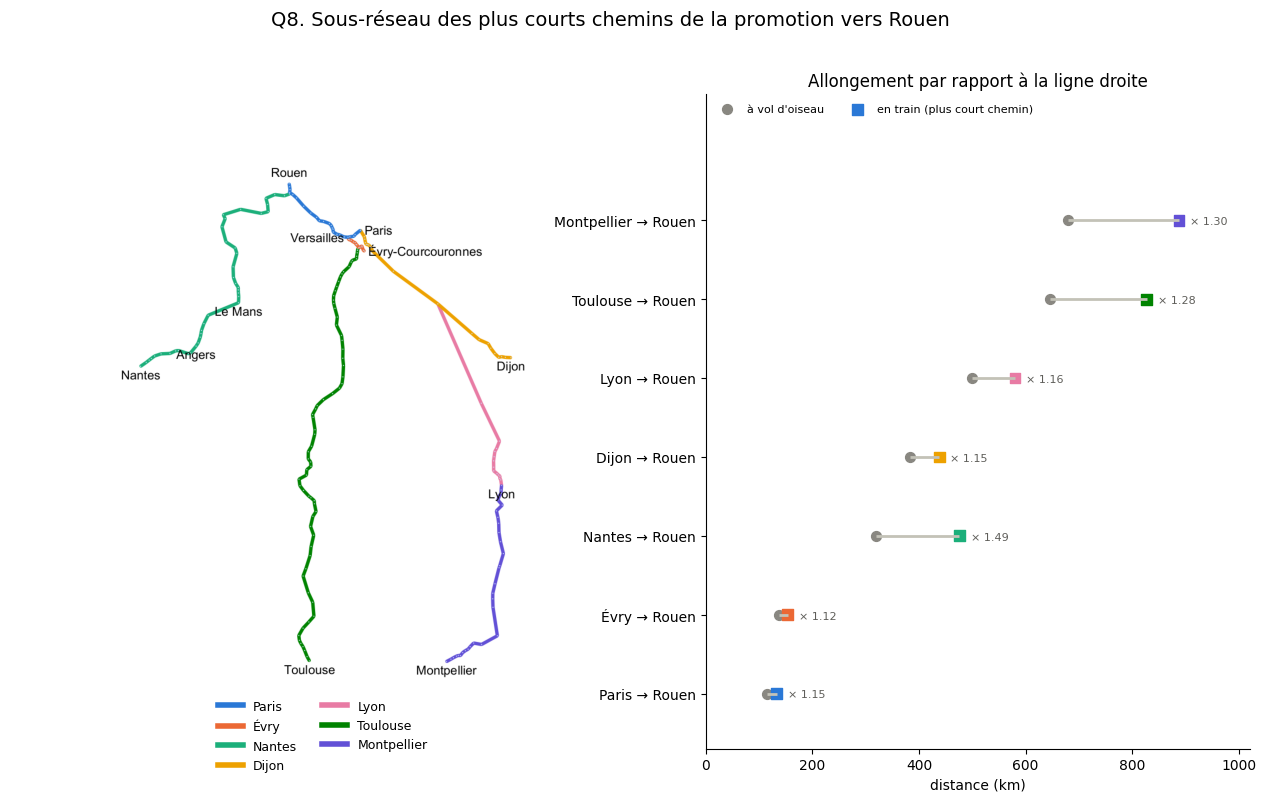

In [9]:
# Dijkstra sur les seules liaisons parcourues par au moins un train (toutes en Île-de-France, faute d'horaires de banlieue)
ROUEN = "76540"
ORIGINES = {"Paris": "75056", "Évry": "91228", "Nantes": "44109", "Dijon": "21231",
            "Lyon": "69123", "Montpellier": "34172", "Toulouse": "31555"}
desservi = P.edge_subgraph([(a, b) for a, b, t in P.edges(data="nb_trains_jour") if t > 0 or (a in IDF and b in IDF)])

trajets = {}
for nom, origine in ORIGINES.items():
    chemin = nx.shortest_path(desservi, origine, ROUEN, weight=KM)
    trajets[nom] = {"chemin": chemin, "train_km": nx.path_weight(desservi, chemin, weight=KM),
                    "vol_oiseau_km": float(np.hypot((villes.lon[origine] - villes.lon[ROUEN]) * 76.6,  # km par degré en France
                                                    (villes.lat[origine] - villes.lat[ROUEN]) * 110.6)),
                    "par_versailles": "78646" in chemin}
trajets = pd.DataFrame(trajets).T.sort_values("vol_oiseau_km")
trajets["detour"] = trajets.train_km.astype(float) / trajets.vol_oiseau_km.astype(float)
display(trajets.drop(columns="chemin"))

# Colonne « trajet » sur les arêtes (une liaison partagée prend la couleur du trajet le plus court)
COULEURS = dict(zip(trajets.index, [BLEU, ORANGE, "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]))
trajet_arete = pd.Series("", index=liaisons.cle)
for nom, chemin in trajets.chemin[::-1].items():
    trajet_arete[[cle_arete(a, b) for a, b in zip(chemin, chemin[1:])]] = nom
colonne(trajet_arete, "trajet_rouen", table="edge")
noeuds = sorted({v for chemin in trajets.chemin for v in chemin})
etiquettes(list(ORIGINES.values()) + [ROUEN, "78646", "49007", "72181"])  # + Versailles, Angers, Le Mans

# Sous-réseau : union des plus courts chemins
sous_reseau = p4c.create_subnetwork(nodes=noeuds, nodes_by_col="cle", edges=list(trajet_arete[trajet_arete != ""].index),
                                    edges_by_col="cle", exclude_edges=True, subnetwork_name="Trajets vers Rouen", network=BASE)
style("Q8", sous_reseau, noeud=2, arete=6, police=22)
p4c.set_edge_color_mapping("trajet_rouen", list(COULEURS), list(COULEURS.values()), mapping_type="d", style_name="Q8")
placer_etiquettes({"75056": "droite", "78646": "gauche", "91228": "droite", "76540": "haut"}, sous_reseau)


def distances(ax):
    y = np.arange(len(trajets))
    ax.hlines(y, trajets.vol_oiseau_km, trajets.train_km, color=GRIS, lw=2)
    ax.scatter(trajets.vol_oiseau_km, y, color="#898781", s=50, label="à vol d'oiseau")
    ax.scatter(trajets.train_km, y, color=[COULEURS[t] for t in trajets.index], s=60, marker="s", label="en train (plus court chemin)")
    for i, (x, r) in enumerate(zip(trajets.train_km, trajets.detour)):
        ax.annotate(f"× {r:.2f}", (x, i), xytext=(8, -3), textcoords="offset points", fontsize=8, color="#5f5e5a")
    ax.set_yticks(y, [f"{t} → Rouen" for t in trajets.index])
    ax.set_xlim(0, trajets.train_km.max() * 1.15)
    ax.set_ylim(-0.7, len(trajets) + 0.6)
    ax.set_xlabel("distance (km)")
    ax.set_title("Allongement par rapport à la ligne droite")
    ax.legend(frameon=False, loc="upper left", fontsize=8, ncol=2)


figure("Q8_rouen", "Q8. Sous-réseau des plus courts chemins de la promotion vers Rouen", reseau=sous_reseau,
       panneaux=[distances], legende=[trait(c, 4, t) for t, c in COULEURS.items()])

*Figure 8.* À gauche, le sous-réseau extrait dans Cytoscape : l'union des plus courts chemins, en km et sur les liaisons parcourues par des trains, des villes d'origine de la promotion jusqu'à Rouen, chaque trajet dans sa couleur. À droite, la longueur de chaque trajet comparée à la ligne droite, avec le facteur d'allongement.

**Réponse :** les sept trajets forment un arbre dont Rouen est la racine, propriété des plus courts chemins vers un même nœud. Six passent par Versailles avant de rejoindre la ligne Paris-Rouen ; seul celui de Nantes arrive par l'ouest, via Angers et Le Mans. Le train allonge les trajets de 12 à 49 % par rapport à la ligne droite. Le pire est Nantes → Rouen (× 1,49), faute de ligne directe entre la Loire et la Normandie. Comme le cours le rappelle, le plus court chemin reste une hypothèse parcimonieuse. Il ignore les changements de train et les horaires, et la fusion des gares d'une ville rend gratuit le passage d'une gare parisienne à une autre. Le trajet Paris → Rouen calculé part donc de la rive gauche, alors que les vrais trains partent de Saint-Lazare.

**Q9. Les régions sont-elles reliées entre elles de façon équilibrée ?**

*Notions du cours.* Regrouper des nœuds selon un **attribut** simplifie un grand graphe, comme on regroupe les métabolites par voie métabolique, ou comme le font les représentations en groupes de nœuds vues en cours (placement par attribut, graphes de puissance). Ici, le **graphe quotient** fusionne toutes les villes d'une même région en un seul nœud ; une arête entre deux régions porte le nombre de liaisons qui les relient.

*Dans Cytoscape.*
- `create_network_from_data_frames` crée le graphe des régions à partir de deux tables ;
- `set_node_property_bypass` place chaque région au barycentre de ses villes ;
- la taille et la couleur des régions et l'épaisseur des arêtes suivent leurs colonnes (correspondances continues) ; `set_edge_label_mapping` affiche le nombre de liaisons sur chaque arête.

,nom,part_communes_avec_gare,part_population_avec_gare,regions_voisines
code,,,,
28,Normandie,3.93,33.2,5
53,Bretagne,9.15,34.4,2
27,Bourgogne-Franche-Comté,5.16,38.8,4
75,Nouvelle-Aquitaine,7.17,39.2,4
84,Auvergne-Rhône-Alpes,7.25,40.9,5
24,Centre-Val de Loire,8.67,42.1,6
76,Occitanie,5.58,43.1,3
52,Pays de la Loire,9.93,44.0,4
44,Grand Est,6.86,44.2,3


Applying default style...
Applying preferred layout


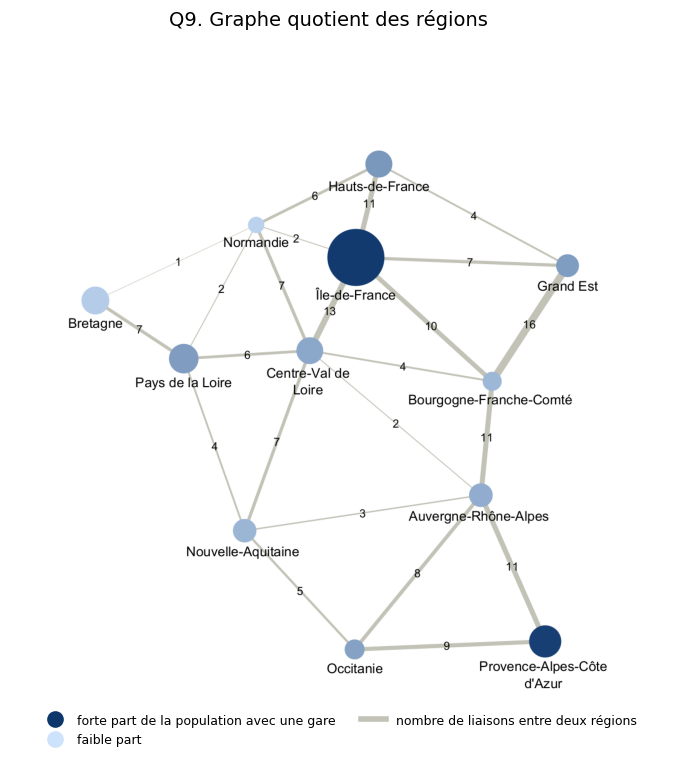

In [10]:
regions = pd.read_csv(DONNEES / "regions.csv", dtype={"code": str}).set_index("code")
blocs = [set(groupe.index) for _, groupe in villes.loc[list(P)].groupby("region")]
R = nx.quotient_graph(P, blocs, relabel=False)
R = nx.relabel_nodes(R, {bloc: villes.region[next(iter(bloc))] for bloc in R})
display(regions.loc[list(R), ["nom", "part_communes_avec_gare", "part_population_avec_gare"]]
        .assign(regions_voisines=[R.degree(r) for r in R]).sort_values("part_population_avec_gare"))

noeuds = regions.loc[list(R)].reset_index().rename(columns={"code": "id"})
aretes = pd.DataFrame([(a, b, w) for a, b, w in R.edges(data="weight")], columns=["source", "target", "liaisons"])
lon = villes.loc[list(P)].groupby("region").lon.mean()[list(R)]
lat = villes.loc[list(P)].groupby("region").lat.mean()[list(R)]
regions_cy = nouveau_reseau(noeuds, aretes, "Graphe des régions", lon * 100, -lat * 145)
style("Q9", regions_cy, arete=2, etiquette="nom", police=26)
p4c.set_edge_font_size_default(22, style_name="Q9")
p4c.set_node_size_mapping("part_communes_avec_gare", [0, float(regions.part_communes_avec_gare.max())], [15, 110], style_name="Q9")
p4c.set_node_color_mapping("part_population_avec_gare", [30, 65], [CLAIR, FONCE], style_name="Q9")
p4c.set_edge_line_width_mapping("liaisons", [1, float(aretes.liaisons.max())], [1, 14], style_name="Q9")
p4c.set_edge_label_mapping("liaisons", style_name="Q9")
figure("Q9_regions", "Q9. Graphe quotient des régions", reseau=regions_cy,
       legende=[point(FONCE, 12, "forte part de la population avec une gare"), point(CLAIR, 12, "faible part"),
                trait(GRIS, 4, "nombre de liaisons entre deux régions")])

*Figure 9.* Le graphe quotient des régions, construit avec NetworkX puis dessiné dans Cytoscape : un nœud par région, placé au barycentre de ses villes. La taille code la part des communes qui ont une gare, la couleur la part de la population qui habite une commune avec gare ; le nombre sur chaque arête est celui des liaisons entre les deux régions.

**Réponse :** non. L'Île-de-France et Provence-Alpes-Côte d'Azur sont les mieux couvertes, avec environ 63 % de la population dans une commune avec gare, contre un tiers seulement en Normandie et en Bretagne. Les liaisons entre régions sont aussi très inégales. La Normandie, région de Rouen, n'est reliée à l'Île-de-France que par 2 liaisons, un goulot d'étranglement pour les trajets de la promotion (Q8). La Bretagne n'est reliée qu'aux Pays de la Loire et à la Normandie, alors que le Grand Est et la Bourgogne-Franche-Comté partagent 16 liaisons. Regrouper les nœuds simplifie le graphe et fait apparaître ces déséquilibres, invisibles à l'échelle des 2 597 villes.

**Q10. Compter des liaisons ou des kilomètres change-t-il les réponses ?**

*Notions du cours.* Le cours pose la question : *« faut-il considérer tous les nœuds et toutes les arêtes comme identiques ? »*. Une mesure **non pondérée** compte des arêtes ; une mesure **pondérée** additionne des poids. Le **diamètre non pondéré** est le plus grand nombre de liaisons à parcourir entre deux villes par le chemin le plus direct : c'est le trajet qui traverse obligatoirement le plus de gares.

*Dans Cytoscape.*
- `analyze_network` (Tools › Analyze Network) ne sait pas utiliser de poids. Ses colonnes `ClosenessCentrality`, `BetweennessCentrality` et `Eccentricity` sont donc calculées en nombre de liaisons ; elles sont relues avec `get_table_columns` et comparées à NetworkX ;
- la couleur des villes suit la colonne `Eccentricity` de Cytoscape, et les deux diamètres sont dessinés par une colonne d'arête (correspondance discrète).

,écart maximal Cytoscape / NetworkX sans poids,"en tête, en liaisons (Cytoscape)","en tête, en km (NetworkX)",corrélation de rang km / liaisons
ClosenessCentrality,1.387779e-17,Montereau-Fault-Yonne,Juvisy-sur-Orge,0.75
BetweennessCentrality,2.275957e-15,Commune Nouvelle D'Arrou,Paris,0.33
Eccentricity,0.000000e+00,Colombier-Saugnieu,Montluçon,0.55


Le plus de gares : Err → Brest, 90 liaisons, 1767 km ; le plus long en km : La Brigue → Brest, 145 liaisons, 1487 km


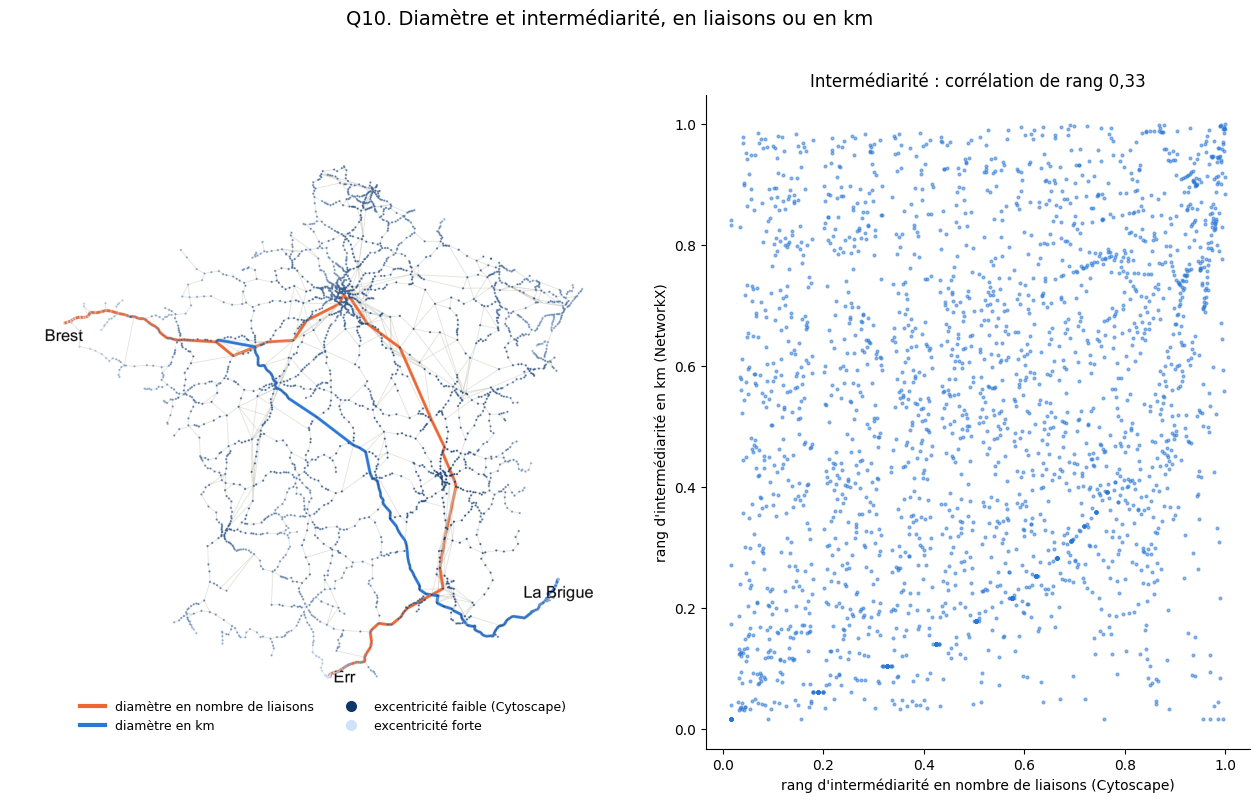

In [11]:
cy = p4c.get_table_columns("node", network=BASE).set_index("cle").loc[list(P)]
sans_poids = pd.DataFrame({"ClosenessCentrality": nx.closeness_centrality(P),
                           "BetweennessCentrality": nx.betweenness_centrality(P),
                           "Eccentricity": nx.eccentricity(P)})
en_km = pd.DataFrame({"ClosenessCentrality": proximite, "BetweennessCentrality": intermediarite, "Eccentricity": excentricite})
tete = lambda s, c: s.idxmin() if c == "Eccentricity" else s.idxmax()  # centre ou maximum
controle = pd.DataFrame({
    "écart maximal Cytoscape / NetworkX sans poids": (cy[sans_poids.columns].astype(float) - sans_poids).abs().max(),
    "en tête, en liaisons (Cytoscape)": [villes.nom[tete(cy[c].astype(float), c)] for c in sans_poids],
    "en tête, en km (NetworkX)": [villes.nom[tete(en_km[c], c)] for c in sans_poids],
    "corrélation de rang km / liaisons": [round(en_km[c].corr(sans_poids[c], method="spearman"), 2) for c in sans_poids]})
display(controle)

# Diamètre en nombre de liaisons : le trajet qui traverse obligatoirement le plus de gares
depart = sans_poids.Eccentricity.idxmax()
liaisons_depuis = nx.single_source_shortest_path_length(P, depart)
arrivee = max(liaisons_depuis, key=liaisons_depuis.get)
plus_d_arrets = nx.shortest_path(P, depart, arrivee)
print(f"Le plus de gares : {villes.nom[depart]} → {villes.nom[arrivee]}, {len(plus_d_arrets) - 1} liaisons, "
      f"{nx.path_weight(P, plus_d_arrets, KM):.0f} km ; le plus long en km : {villes.nom[bout1]} → {villes.nom[bout2]}, "
      f"{len(diametre) - 1} liaisons, {excentricite.max():.0f} km")

chemins = pd.Series("", index=liaisons.cle)
chemins[[cle_arete(a, b) for a, b in zip(diametre, diametre[1:])]] = "km"
chemins[[cle_arete(a, b) for a, b in zip(plus_d_arrets, plus_d_arrets[1:])]] = "liaisons"
colonne(chemins, "diametre_q10", table="edge")
etiquettes([depart, arrivee, bout1])
style("Q10", noeud=5)
placer_etiquettes({depart: "droite"}, BASE)  # Err est au bord sud de la carte : étiquette à droite, pas dessous
p4c.set_node_color_mapping("Eccentricity", [float(cy.Eccentricity.min()), float(cy.Eccentricity.max())], [FONCE, CLAIR], style_name="Q10")
p4c.set_edge_color_mapping("diametre_q10", ["liaisons", "km"], [ORANGE, BLEU], mapping_type="d", style_name="Q10")
p4c.set_edge_line_width_mapping("diametre_q10", ["liaisons", "km"], [7, 7], mapping_type="d", style_name="Q10")


def rangs(ax):
    ax.scatter(sans_poids.BetweennessCentrality.rank(pct=True), en_km.BetweennessCentrality.rank(pct=True), s=4, color=BLEU, alpha=0.5)
    ax.set_xlabel("rang d'intermédiarité en nombre de liaisons (Cytoscape)")
    ax.set_ylabel("rang d'intermédiarité en km (NetworkX)")
    rho = controle.loc["BetweennessCentrality", "corrélation de rang km / liaisons"]
    ax.set_title(f"Intermédiarité : corrélation de rang {rho}".replace(".", ","))


figure("Q10_km_ou_liaisons", "Q10. Diamètre et intermédiarité, en liaisons ou en km", panneaux=[rangs],
       legende=[trait(ORANGE, 3, "diamètre en nombre de liaisons"), trait(BLEU, 3, "diamètre en km"),
                point(FONCE, 8, "excentricité faible (Cytoscape)"), point(CLAIR, 8, "excentricité forte")])

*Figure 10.* À gauche, les villes colorées selon l'excentricité calculée par Cytoscape, en nombre de liaisons, avec les deux diamètres : en orange le trajet qui traverse le plus de gares, en bleu le trajet le plus long en km. À droite, chaque point est une ville : son rang d'intermédiarité en nombre de liaisons (Cytoscape) contre son rang en km (NetworkX).

**Réponse :** oui, et beaucoup. Sans poids, Cytoscape et NetworkX donnent les mêmes valeurs à l'arrondi près : les deux outils sont fiables. Mais *Analyze Network* ignore les km, et compter des liaisons change les réponses. Le trajet qui traverse le plus de gares relie Err (Pyrénées-Orientales) à Brest, en passant par Paris et les lignes à grande vitesse, où les gares sont rares. Le plus long en km relie La Brigue à Brest par le Massif central. Le centre passe de Montluçon à Colombier-Saugnieu, et les deux classements d'intermédiarité ne se ressemblent presque plus (corrélation de rang de 0,33). C'est pourquoi les mesures en km sont calculées dans NetworkX, puis seulement affichées dans Cytoscape.

## Conclusion

Le réseau ferré français est une étoile centrée sur Paris, que dessinent ses lignes à grande vitesse (Q1), ses trains (Q2), son centre (Q5) et ses points névralgiques (Q6). Ce n'est ni un réseau sans échelle, faute de carrefours géants (Q3), ni un petit monde, faute de raccourcis (Q4) : la géographie l'en empêche. Il résiste bien à la perte de ses villes les plus centrales, au prix de trajets plus longs, mais il est fragile en périphérie, sur les lignes en cul-de-sac (Q7). Les méthodes du cours s'y appliquent bien, à condition de choisir la mesure adaptée à la question et de bien définir les nœuds et les poids (Q3, Q10). Les limites tiennent aux données et au modèle : un nœud par ville, des distances en km et non en temps, des changements de train ignorés, des trains de banlieue absents des horaires, et un seul jour observé.